# مسابقات تنیس
**امیر کارگر — ستاره بهرامی — ندا مردی**


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import MaxNLocator
from IPython.display import display as ipy_display, Markdown

PROJECT_ROOT_OVERRIDE = ''  
start_dir = Path(PROJECT_ROOT_OVERRIDE).expanduser() if PROJECT_ROOT_OVERRIDE else Path.cwd()
candidates = [start_dir, *start_dir.parents]
ROOT = next((p for p in candidates if (p/'data/input/tennis_project_data_package/silver').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Extract the complete ZIP, open its project folder, or set PROJECT_ROOT_OVERRIDE to the extracted project folder.')
PACKAGE = ROOT/'data/input/tennis_project_data_package'
OUT = ROOT/'data/output'
FIG = ROOT/'figures'
for folder in (OUT, FIG): folder.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 25)
plt.rcParams.update({'font.family':'DejaVu Sans', 'figure.dpi':110})

sns.set_theme(style='white', font='DejaVu Sans', rc={'axes.titleweight':'bold','axes.labelcolor':'#0F3826','text.color':'#0F3826'})

In [2]:
file_map = {
    'event':'clean_match_event', 'home_team':'clean_match_home_team',
    'away_team':'clean_match_away_team', 'home_team_score':'clean_match_home_score',
    'away_team_score':'clean_match_away_score', 'tournament':'clean_match_tournament',
    'season':'clean_match_season', 'round':'clean_match_round',
    'venue':'clean_match_venue', 'time':'clean_match_time', 'statistics':'clean_statistics'
}
tables = {}
load_log = []
for family, filename in file_map.items():
    started = time.perf_counter()
    tables[family] = pd.read_parquet(PACKAGE/'silver'/f'{filename}.parquet')
    load_log.append({'table':family, 'rows':len(tables[family]), 'seconds':round(time.perf_counter()-started,3)})
gold_check = pd.read_parquet(PACKAGE/'gold/gold_match_fact_v3.parquet',
    columns=['match_id','winner_code','has_home_player','has_away_player','has_winner'])
assert gold_check.match_id.is_unique
assert set(gold_check.match_id)==set(tables['event'].match_id)
check = gold_check.merge(tables['event'][['match_id','winner_code']],on='match_id',validate='one_to_one',suffixes=('_gold','_silver'))
assert check.winner_code_gold.fillna(-999).eq(check.winner_code_silver.fillna(-999)).all()
assert gold_check.has_home_player.eq(gold_check.match_id.isin(tables['home_team'].match_id)).all()
assert gold_check.has_away_player.eq(gold_check.match_id.isin(tables['away_team'].match_id)).all()
ipy_display(pd.DataFrame(load_log))
print('Gold/Silver match IDs, winners and player-coverage flags agree.')


,table,rows,seconds
0,event,16873,0.080
1,home_team,12389,0.008
2,away_team,11690,0.008
3,home_team_score,16873,0.008
4,away_team_score,16873,0.008
5,tournament,16873,0.008
6,season,16873,0.007
7,round,9243,0.007
8,venue,16749,0.008
9,time,16873,0.008


Gold/Silver match IDs, winners and player-coverage flags agree.


In [3]:
def numeric(series):
    return pd.to_numeric(series, errors='coerce')

def ids(frame):
    frame = frame.copy()
    frame['match_id'] = numeric(frame['match_id']).astype('Int64')
    return frame
tables = {k: ids(v) for k, v in tables.items()}
quality = []
for name, frame in tables.items():
    quality.append({'table': name, 'rows': len(frame), 'exact_duplicates': int(frame.duplicated().sum()), 'missing_match_id': int(frame.match_id.isna().sum())})
    tables[name] = frame.drop_duplicates().copy()
    if name != 'statistics' and tables[name].match_id.duplicated().any():
        raise ValueError(f'Conflicting match rows in {name}; inspect rather than silently choosing.')
ipy_display(pd.DataFrame(quality))
event = tables['event'].copy()
event['date'] = pd.to_datetime(numeric(event.start_datetime), unit='s', utc=True, errors='coerce')
event['winner_code'] = numeric(event.winner_code)
m = event[['match_id', 'date', 'winner_code', 'default_period_count']].copy()
for family, prefix in [('home_team', 'h_'), ('away_team', 'a_'), ('home_team_score', 'hs_'), ('away_team_score', 'as_'), ('time', 't_'), ('tournament', 'tour_'), ('round', 'round_'), ('season', 'season_'), ('venue', 'venue_')]:
    f = tables[family].rename(columns=lambda c: c if c == 'match_id' else prefix + c)
    m = m.merge(f, on='match_id', how='left', validate='one_to_one')
for side in ['h_', 'a_']:
    for col in ['player_id', 'height', 'current_rank']:
        m[side + col] = numeric(m[side + col])
individual = m.h_player_id.notna() & m.a_player_id.notna()
matches = m.loc[individual & m.winner_code.isin([1, 2])].copy()
matches['gender'] = matches.h_gender.where(matches.h_gender.eq(matches.a_gender), 'Unknown')
appearances = []
for side, other, winner in [('h_', 'a_', 1), ('a_', 'h_', 2)]:
    p = matches[['match_id', 'date', 'gender']].copy()
    for col in ['player_id', 'name', 'height', 'current_rank', 'country', 'plays']:
        p[col] = matches[side + col].values
    p['opponent_rank'] = matches[other + 'current_rank'].values
    p['won'] = matches.winner_code.eq(winner).values
    p['side'] = side
    appearances.append(p)
long = pd.concat(appearances, ignore_index=True)
profiles = []
for family in ['home_team', 'away_team']:
    f = tables[family].merge(event[['match_id', 'date']], on='match_id', validate='one_to_one')
    f['player_id'] = numeric(f.player_id)
    profiles.append(f.loc[f.player_id.notna()])
profile_history = pd.concat(profiles, ignore_index=True).sort_values(['date', 'match_id'], na_position='first')
static_columns = ['name', 'full_name', 'gender', 'height', 'plays', 'country']
profile_history[static_columns] = profile_history.groupby('player_id')[static_columns].ffill()
players = profile_history.drop_duplicates('player_id', keep='last').copy()
players['height_cm'] = numeric(players.height) * 100
players['rank'] = numeric(players.current_rank).where(numeric(players.current_rank) > 0)
names = players.set_index('player_id')['name']
for i in range(1, 6):
    for prefix in ['hs_', 'as_', 't_']:
        matches[f'{prefix}period_{i}'] = numeric(matches[f'{prefix}period_{i}'])
score_h = matches[[f'hs_period_{i}' for i in range(1, 6)]].to_numpy(float)
score_a = matches[[f'as_period_{i}' for i in range(1, 6)]].to_numpy(float)
complete = (np.maximum(score_h, score_a) == 6) & (np.minimum(score_h, score_a) <= 4) | (np.maximum(score_h, score_a) == 7) & np.isin(np.minimum(score_h, score_a), [5, 6])
matches['completed_standard_sets'] = complete.sum(axis=1)
matches['sets_recorded'] = np.sum(np.isfinite(score_h) & np.isfinite(score_a) & (score_h + score_a > 0), axis=1)
TIME_UNIT = 'seconds'
period_times = matches[[f't_period_{i}' for i in range(1, 6)]].where(lambda x: x > 0)
print('Nonpositive raw period times treated as unavailable:', int((matches[[f't_period_{i}' for i in range(1, 6)]] <= 0).sum().sum()))
matches['duration_hours'] = period_times.sum(axis=1, min_count=1) / (3600 if TIME_UNIT == 'seconds' else 60)
matches['duration_complete'] = ~(np.isfinite(score_h) & np.isfinite(score_a) & (score_h + score_a > 0) & period_times.isna().to_numpy()).any(axis=1)
stats = tables['statistics'].copy()
stats = stats.loc[stats.period.astype(str).str.upper().eq('ALL')].copy()
if stats.duplicated(['match_id', 'statistic_name']).any():
    raise ValueError('Conflicting ALL statistics; inspect before aggregating.')
def stat(name):
    f = stats.loc[stats.statistic_name.eq(name)].set_index('match_id')
    return pd.DataFrame({c: numeric(f[c]) for c in ['home_value', 'away_value', 'home_total', 'away_total']}).reindex(matches.match_id)
def pair_total(name):
    f = stat(name)
    return f[['home_value', 'away_value']].sum(axis=1, min_count=2)
def save_result(number, frame):
    if isinstance(frame, pd.Series):
        frame = frame.to_frame()
    frame.to_csv(OUT / f'q{number:02d}.csv', index=True, encoding='utf-8-sig')
    ipy_display(frame.head(25))
def explain(text):
    ipy_display(Markdown(text))
ipy_display(pd.DataFrame({'measure': ['All events', 'Individual result-bearing matches', 'Unique players'], 'count': [len(m), len(matches), len(players)]}))
ipy_display(stats.statistic_name.value_counts())

,table,rows,exact_duplicates,missing_match_id
0,event,16873,0,0
1,home_team,12389,0,0
2,away_team,11690,0,0
3,home_team_score,16873,0,0
4,away_team_score,16873,0,0
5,tournament,16873,0,0
6,season,16873,0,0
7,round,9243,0,0
8,venue,16749,0,0
9,time,16873,0,0


Nonpositive raw period times treated as unavailable: 3


,measure,count
0,All events,16873
1,Individual result-bearing matches,8828
2,Unique players,2644


statistic_name
break_points_saved            11393
first_serve_return_points     11393
second_serve_return_points    11393
break_points_converted        11393
aces                          11389
double_faults                 11389
service_points_won            11389
max_points_in_a_row           11384
first_serve                   11381
first_serve_points            11379
second_serve                  11377
second_serve_points           11375
total                         11357
service_games_won             11357
service_games_played          11349
receiver_points_won           11349
return_games_played           11349
tiebreaks                     11270
max_games_in_a_row            11259
total_won                     11209
Name: count, dtype: int64

## 01
## چند بازیکن تنیس در مجموعه داده وجود دارد؟
## How many tennis players are included in the dataset?


In [4]:
q01_r = players.assign(gender=players.gender.fillna('Unknown')).groupby('gender').size().rename('Players')
q01_answer = len(players)
print('Unique individual players:', q01_answer)
save_result(1, q01_r)

Unique individual players: 2644


,Players
gender,
F,1234
M,1404
Unknown,6


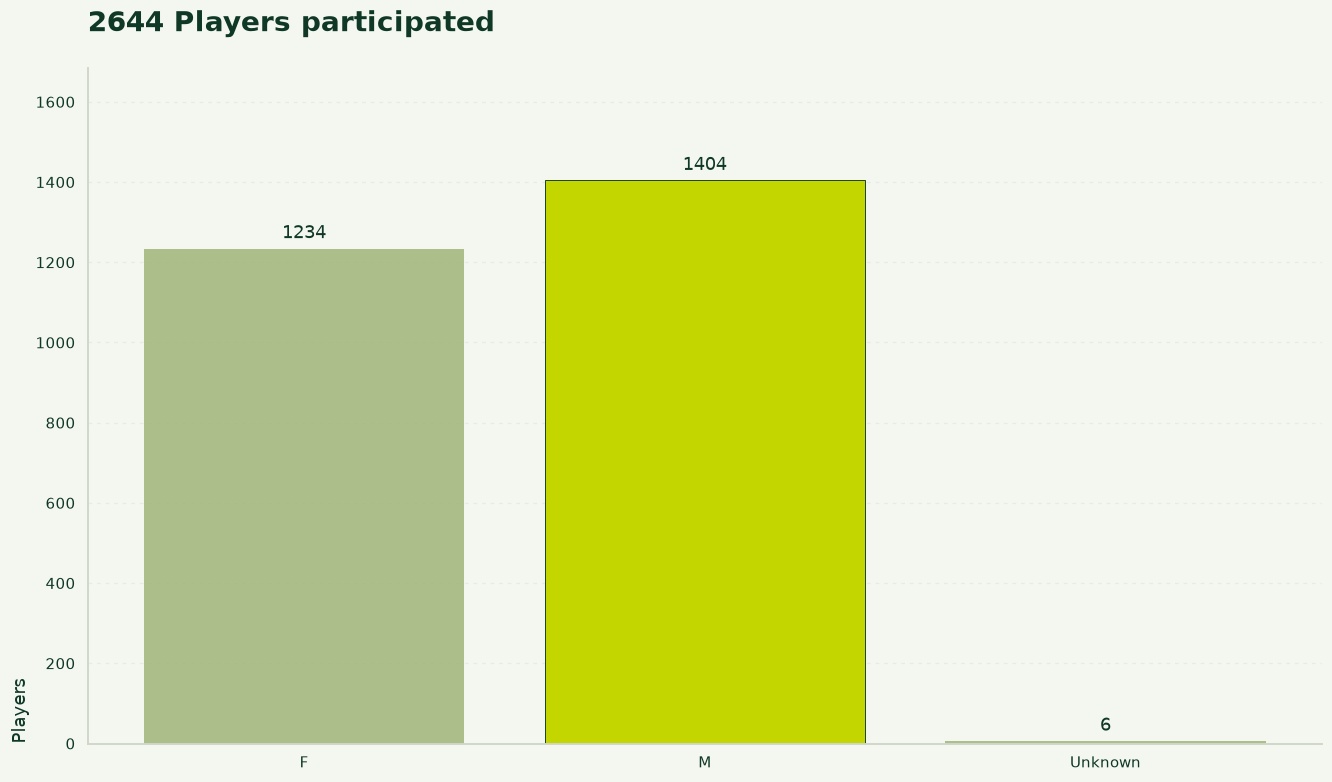

In [5]:
q01_CREAM = '#F4F6F0'
q01_WHITE = '#FFFFFF'
q01_LIME = '#C4D600'
q01_OLIVE = '#5A7263'
q01_GREEN = '#0F3826'
q01_RED = '#C86D51'
q01_GRAY = '#98B06F'
q01_INK = '#0F3826'
q01_fig, q01_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q01_fig.set_facecolor(q01_CREAM)
q01_ax.set_facecolor(q01_WHITE)
q01_mask = (
    q01_r.index.astype(str).str.strip().str.lower()!= 'unknown')
q01_shown = q01_r[q01_mask]
q01_shown = q01_r
q01_ax.bar(q01_shown.index.astype(str), q01_shown.values, color=[q01_GREEN if q01_v == q01_shown.max() else q01_GRAY for q01_v in q01_shown])
q01_ax.bar_label(q01_ax.containers[0], fmt='%.0f', padding=4, color=q01_INK)
q01_ax.margins(y=0.2)
for q01_bar in q01_ax.containers[0]:
    q01_bar.set_edgecolor('none')
    q01_bar.set_alpha(0.78)
q01_peak = max((q01_bar.get_width() if 1 in [3,6,9] else q01_bar.get_height()) for q01_bar in q01_ax.containers[0])
for q01_bar in q01_ax.containers[0]:
    if abs((q01_bar.get_width() if 1 in [3,6,9] else q01_bar.get_height()) - q01_peak) < 1e-9:
        q01_bar.set_facecolor(q01_LIME)
        q01_bar.set_edgecolor(q01_GREEN)
        q01_bar.set_linewidth(0.6)
        q01_bar.set_alpha(1)
q01_ax.set_title('2644 Players participated', loc='left', fontsize=18, fontweight='bold', color=q01_INK, pad=24)
q01_ax.set_ylabel('Players', fontsize=12, color=q01_INK,loc= 'bottom')
q01_ax.spines[['top', 'right']].set_visible(False)
q01_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q01_ax.tick_params(colors=q01_INK, labelsize=10)
q01_ax.set_axisbelow(True)
q01_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q01_fig.set_facecolor(q01_CREAM)
q01_ax.set_facecolor(q01_WHITE)
q01_ax.patch.set_alpha(0)
sns.despine(ax=q01_ax, top=True, right=True)
q01_ax.tick_params(length=0, pad=8)
q01_fig.savefig(FIG/'q01.svg',bbox_inches='tight',facecolor=q01_CREAM)
q01_fig.savefig(FIG / 'q01.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q01_fig)

**پاسخ محاسبه‌شده: 2644**

در مجموع ۲٬۶۴۴ بازیکن منحصربه‌فرد در داده وجود دارد. از این تعداد، ۱٬۴۰۴ نفر مرد، ۱٬۲۳۴ نفر زن و ۶ نفر بدون جنسیت مشخص هستند.

## 02
## میانگین قد بازیکنان چقدر است؟

## What is the average height of the players?


In [6]:
q02_r = players.height_cm.dropna()
q02_answer = q02_r.mean()
print(f'Mean: {q02_answer:.2f} cm; known: {len(q02_r)}/{len(players)}')
save_result(2, q02_r)

Mean: 182.20 cm; known: 1344/2644


,height_cm
46,169.0
12413,185.0
289,191.0
12683,203.0
403,162.0
300,183.0
485,178.0
12862,170.0
12980,188.0
436,191.0


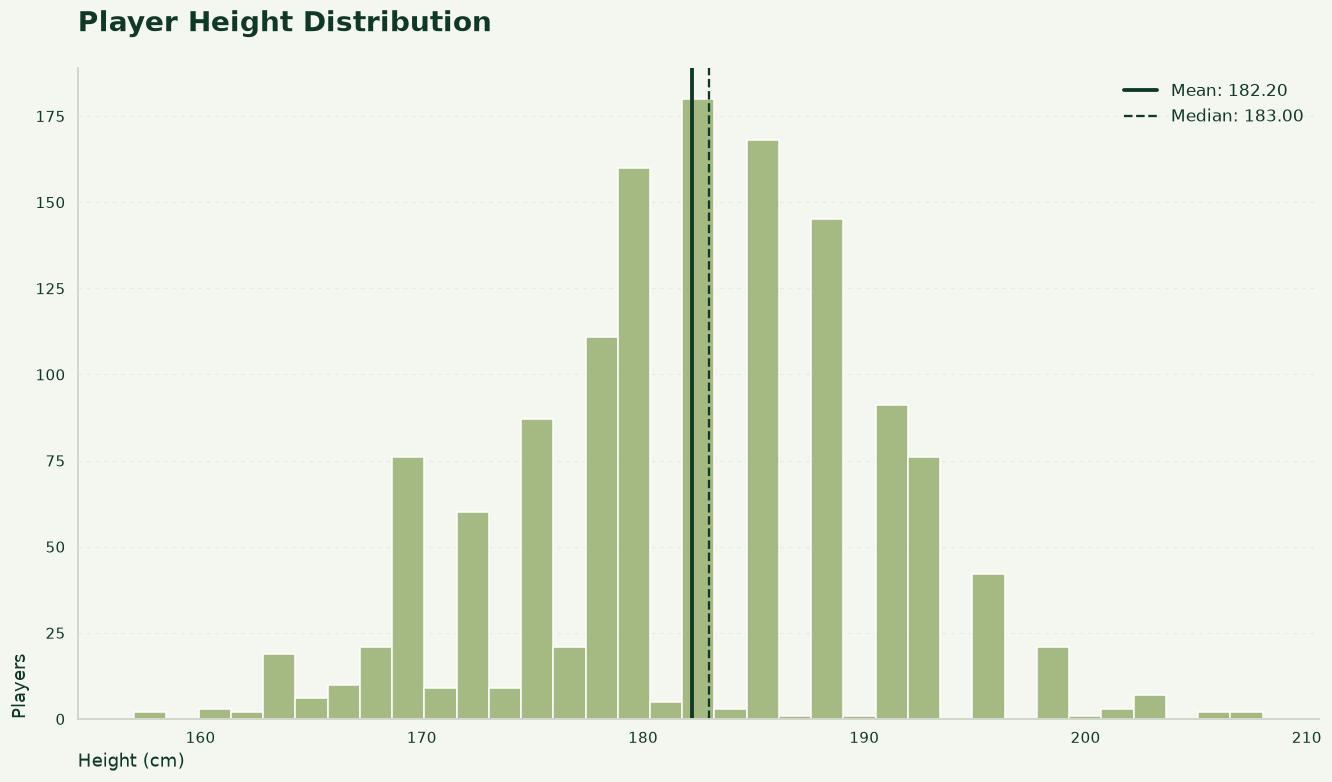

In [7]:
q02_CREAM = '#F4F6F0'
q02_WHITE = '#FFFFFF'
q02_LIME = '#C4D600'
q02_OLIVE = '#5A7263'
q02_GREEN = '#0F3826'
q02_RED = '#C86D51'
q02_GRAY = '#98B06F'
q02_INK = '#0F3826'
q02_fig, q02_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q02_fig.set_facecolor(q02_CREAM)
q02_ax.set_facecolor(q02_WHITE)
q02_values = pd.to_numeric(q02_r, errors='coerce').dropna()
sns.histplot(x=q02_values, bins=35, color=q02_GRAY, edgecolor='white', alpha=0.85, ax=q02_ax)
q02_ax.axvline(q02_values.mean(), color=q02_GREEN, lw=2.5, label=f'Mean: {q02_values.mean():.2f}')
q02_ax.axvline(q02_values.median(), color=q02_INK, lw=1.5, ls='--', label=f'Median: {q02_values.median():.2f}')
q02_ax.legend(frameon=False)
q02_ax.set_ylabel('Matches' if False else 'Players', loc= 'bottom')
q02_ax.set_title('Player Height Distribution', loc='left', fontsize=18, fontweight='bold', color=q02_INK, pad=24)
q02_ax.set_xlabel('Height (cm)', fontsize=12, color=q02_INK, loc='left')
q02_ax.spines[['top', 'right']].set_visible(False)
q02_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q02_ax.tick_params(colors=q02_INK, labelsize=10)
q02_ax.set_axisbelow(True)
q02_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q02_fig.set_facecolor(q02_CREAM)
q02_ax.set_facecolor(q02_WHITE)
q02_ax.patch.set_alpha(0)
sns.despine(ax=q02_ax, top=True, right=True)
q02_ax.tick_params(length=0, pad=8)
q02_fig.savefig(FIG/'q02.svg',bbox_inches='tight',facecolor=q02_CREAM)
q02_fig.savefig(FIG / 'q02.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q02_fig)

**پاسخ محاسبه‌شده: 182.20**

میانگین قد بازیکنان دارای مقدار معتبر حدود ۱۸۲٫۲۱ سانتی‌متر است و میانهٔ قد تقریباً ۱۸۳ سانتی‌متر به دست آمده است. اطلاعات قد برای حدود ۱٬۳۴۸ بازیکن از ۲٬۶۳۸ بازیکن دارای جنسیت مشخص ثبت شده، بنابراین پوشش داده حدود ۵۱٪ است. به همین دلیل این میانگین باید فقط به‌عنوان میانگین بازیکنان دارای قد ثبت‌شده تفسیر شود، نه کل بازیکنان دیتاست.

## 03
## کدام بازیکن بیشترین تعداد برد را دارد؟

## Which player has the highest number of wins?

In [8]:
q03_r = long.loc[long.won].groupby('player_id').size().sort_values(ascending=False).rename('Wins')
q03_r.index = q03_r.index.map(names)
q03_answer = q03_r.max()
print('Joint leaders:', q03_r[q03_r.eq(q03_answer)].to_dict())
save_result(3, q03_r)

Joint leaders: {'Popko D.': 27}


,Wins
player_id,
Popko D.,27
Chidekh C.,22
Dellien Velasco M.,20
Gengel M.,19
Jianu F.,18
Faria J.,18
Clarke J.,18
Collins D.,18
Bolt A.,17


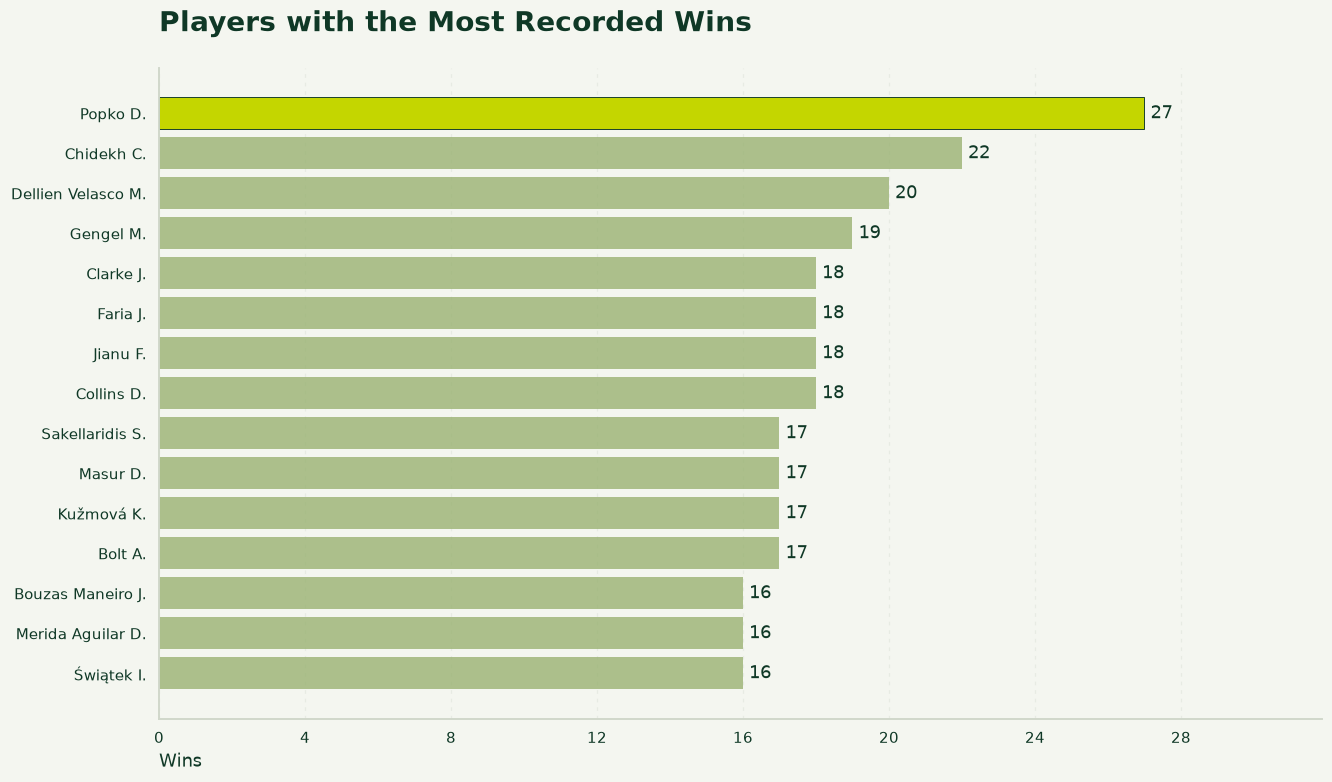

In [9]:
q03_CREAM = '#F4F6F0'
q03_WHITE = '#FFFFFF'
q03_LIME = '#C4D600'
q03_OLIVE = '#5A7263'
q03_GREEN = '#0F3826'
q03_RED = '#C86D51'
q03_GRAY = '#98B06F'
q03_INK = '#0F3826'
q03_fig, q03_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q03_fig.set_facecolor(q03_CREAM)
q03_ax.set_facecolor(q03_WHITE)
q03_shown = q03_r.head(15).sort_values()
q03_colors = [q03_GREEN if q03_v == q03_shown.max() else q03_GRAY for q03_v in q03_shown]
q03_ax.barh(q03_shown.index.astype(str), q03_shown.values, color=q03_colors)
q03_ax.bar_label(q03_ax.containers[0], fmt='%.0f', padding=4, color=q03_INK)
q03_ax.margins(x=0.18)
for q03_bar in q03_ax.containers[0]:
    q03_bar.set_edgecolor('none')
    q03_bar.set_alpha(0.78)
q03_peak = max((q03_bar.get_width() if 3 in [3,6,9] else q03_bar.get_height()) for q03_bar in q03_ax.containers[0])
for q03_bar in q03_ax.containers[0]:
    if abs((q03_bar.get_width() if 3 in [3,6,9] else q03_bar.get_height()) - q03_peak) < 1e-9:
        q03_bar.set_facecolor(q03_LIME)
        q03_bar.set_edgecolor(q03_GREEN)
        q03_bar.set_linewidth(0.6)
        q03_bar.set_alpha(1)
q03_ax.set_title('Players with the Most Recorded Wins', loc='left', fontsize=18, fontweight='bold', color=q03_INK, pad=24)
q03_ax.set_xlabel('Wins', fontsize=12, color=q03_INK, loc='left')
q03_ax.spines[['top', 'right']].set_visible(False)
q03_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q03_ax.tick_params(colors=q03_INK, labelsize=10)
q03_ax.set_axisbelow(True)
q03_ax.grid(axis='x', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q03_fig.set_facecolor(q03_CREAM)
q03_ax.set_facecolor(q03_WHITE)
q03_ax.patch.set_alpha(0)
sns.despine(ax=q03_ax, top=True, right=True)
q03_ax.tick_params(length=0, pad=8)
q03_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
q03_fig.savefig(FIG/'q03.svg',bbox_inches='tight',facecolor=q03_CREAM)
q03_fig.savefig(FIG / 'q03.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q03_fig)

**پاسخ محاسبه‌شده: Popko D**

Popko D. با ۲۷ برد موفق‌ترین بازیکن در دادهٔ موجود است. پس از او Chidekh C. با ۲۲ برد و Dellien Velasco M. با ۲۰ برد قرار دارند. اختلاف پنج‌بردی نفر اول با نفر دوم نشان می‌دهد Popko D. در این نمونه عملکرد برجسته‌ای داشته است

## 04
## طولانی‌ترین زمان ثبت‌شده مسابقه چند ساعت است؟

## What is the longest match recorded in terms of duration?

**پاسخ محاسبه‌شده: {'Loser': 40.707612620153135, 'Winner': 52.52979445656788}**

برندگان به‌طور میانگین ۵۲٫۵۳٪ از امتیازهای سرویس دوم خود را برده‌اند، درحالی‌که این مقدار برای بازندگان ۴۰٫۷۱٪ است. اختلاف ۱۱٫۸۲ واحد درصدی نشان می‌دهد که کیفیت بازی روی سرویس دوم یکی از مهم‌ترین عوامل تمایز برنده و بازنده است. بااین‌حال، این رابطه توصیفی است و به‌تنهایی علت قطعی پیروزی را ثابت نمی‌کند.

In [10]:

q04_raw = (
    matches[['match_id', 'h_name', 'a_name', 'date', 'duration_hours', 'duration_complete']]
    .dropna(subset=['duration_hours'])
    .sort_values('duration_hours', ascending=False)
)
q04_raw_answer = q04_raw['duration_hours'].max()
print(f'Raw maximum duration: {q04_raw_answer:.2f} hours')
display(q04_raw.head(2))
save_result(4, q04_raw.set_index('match_id')['duration_hours'])

Raw maximum duration: 93.55 hours


,match_id,h_name,a_name,date,duration_hours,duration_complete
2898,12063611,Shapatava S.,Branstine C.,2024-02-13 11:00:00+00:00,93.552778,True
2894,12063587,Podlinska M.,Vargová N.,2024-02-13 11:00:00+00:00,88.952778,True


,duration_hours
match_id,
12063611,93.552778
12063587,88.952778
12185562,49.203056
12121829,48.170833
12054403,45.523056
12063588,45.286944
12063582,45.095556
12063615,44.946111
12053865,44.673611


In [11]:

q04_clean = (
    matches.set_index('match_id').loc[lambda df: df['duration_hours'].notna()& df['duration_hours'].gt(0)& df['duration_hours'].lt(50)].sort_values('duration_hours', ascending=False))
q04_answer = q04_clean['duration_hours'].max()
q04_excluded = q04_raw[q04_raw['duration_hours'].ge(50)]
print(f'Clean maximum duration: {q04_answer:.2f} hours')
print(f'Equivalent minutes: {q04_answer * 60:.1f} minutes')
print(f'Excluded quality-review records: {len(q04_excluded)}')
display(q04_clean.head(10).reset_index()[
    ['match_id', 'h_name', 'a_name', 'date', 'duration_hours', 'duration_complete']])
q04_clean_output = q04_clean.reset_index()[
    ['match_id', 'h_name', 'a_name', 'date', 'duration_hours', 'duration_complete']].set_index('match_id')
save_result(4, q04_clean_output)


Clean maximum duration: 49.20 hours
Equivalent minutes: 2952.2 minutes
Excluded quality-review records: 2


,match_id,h_name,a_name,date,duration_hours,duration_complete
0,12185562,Gavrilă O.,Alves C.,2024-03-23 17:00:00+00:00,49.203056,True
1,12121829,Carou I.,Rybakov A.,2024-03-03 13:30:00+00:00,48.170833,True
2,12054403,Gjorcheska L.,Würth T.,2024-02-09 10:00:00+00:00,45.523056,True
3,12063588,Spiridon D.,Martinez L.,2024-02-13 11:00:00+00:00,45.286944,True
4,12063582,Baroni N.,Nesterov A.,2024-02-13 11:00:00+00:00,45.095556,True
5,12063615,Fita Boluda Á.,Chiesa D.,2024-02-13 11:00:00+00:00,44.946111,True
6,12053865,Erhard M.,Melzer G.,2024-02-09 10:00:00+00:00,44.673611,True
7,12063583,Gola A.,Shyla Y.,2024-02-13 11:00:00+00:00,44.595556,True
8,12151570,Monferrer E.,La Serna J.,2024-03-13 19:55:00+00:00,44.009167,True
9,12110886,Clark E.,Gorokhov M.,2024-02-29 11:25:00+00:00,43.400556,True


,h_name,a_name,date,duration_hours,duration_complete
match_id,,,,,
12185562,Gavrilă O.,Alves C.,2024-03-23 17:00:00+00:00,49.203056,True
12121829,Carou I.,Rybakov A.,2024-03-03 13:30:00+00:00,48.170833,True
12054403,Gjorcheska L.,Würth T.,2024-02-09 10:00:00+00:00,45.523056,True
12063588,Spiridon D.,Martinez L.,2024-02-13 11:00:00+00:00,45.286944,True
12063582,Baroni N.,Nesterov A.,2024-02-13 11:00:00+00:00,45.095556,True
12063615,Fita Boluda Á.,Chiesa D.,2024-02-13 11:00:00+00:00,44.946111,True
12053865,Erhard M.,Melzer G.,2024-02-09 10:00:00+00:00,44.673611,True
12063583,Gola A.,Shyla Y.,2024-02-13 11:00:00+00:00,44.595556,True
12151570,Monferrer E.,La Serna J.,2024-03-13 19:55:00+00:00,44.009167,True


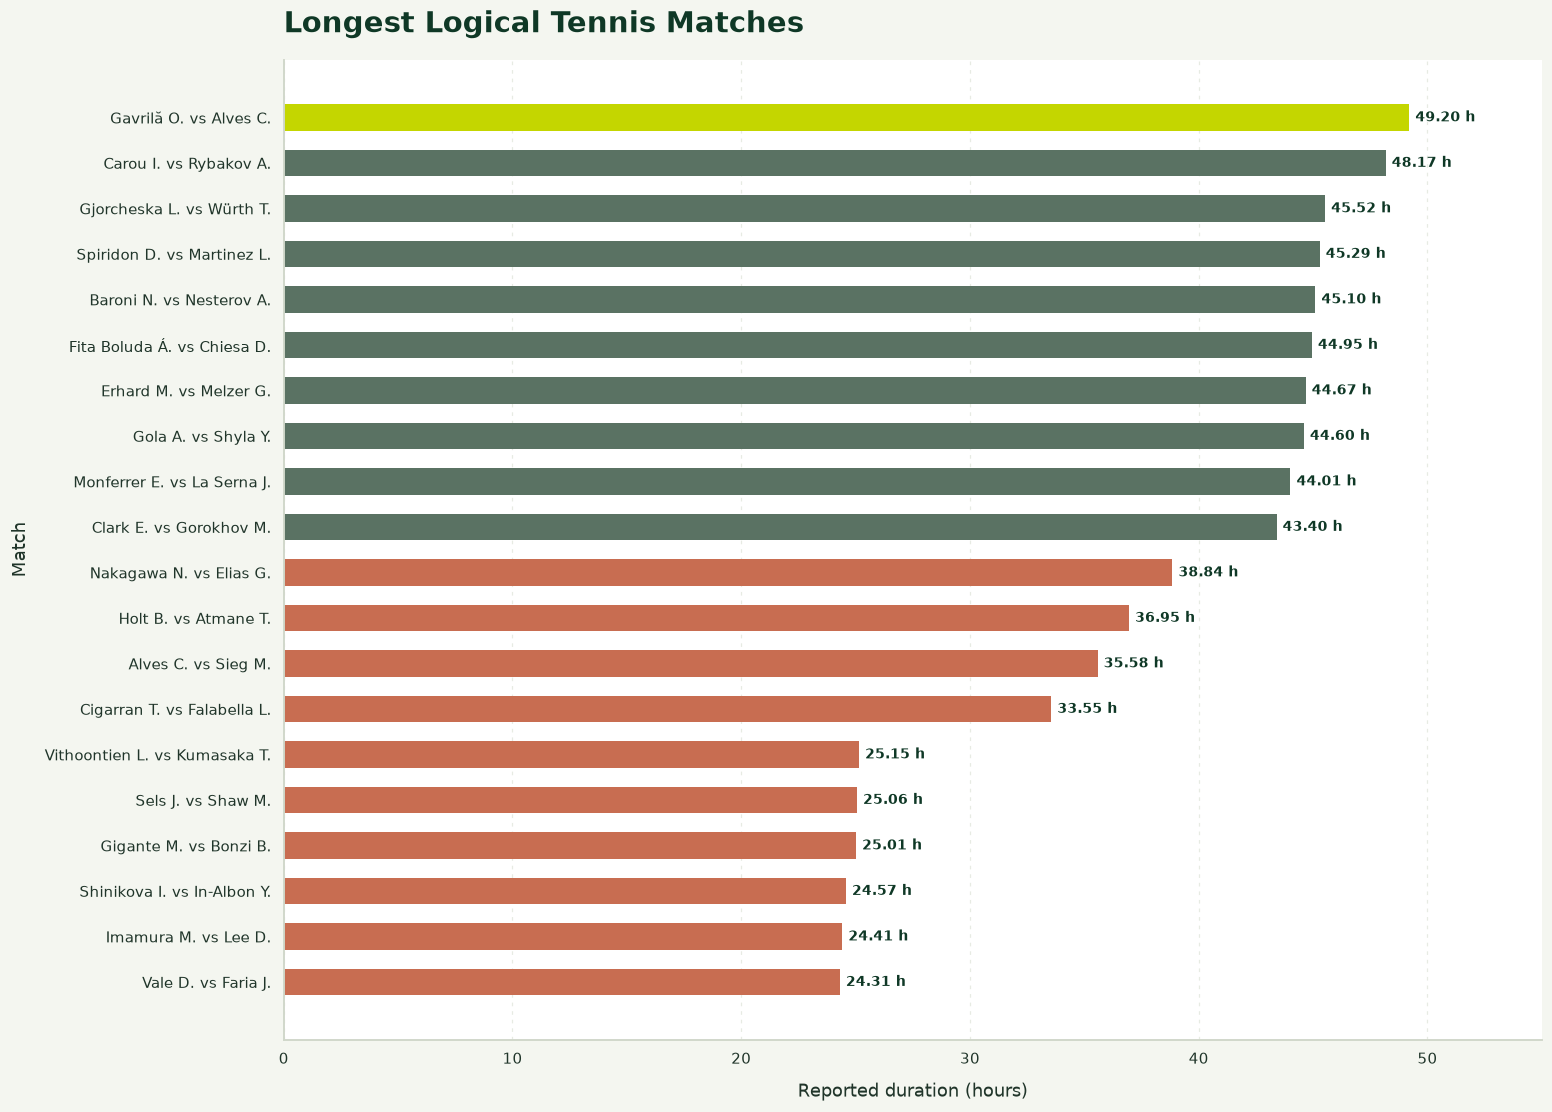

In [12]:
q04_BG = '#F4F6F0'
q04_WHITE = '#FFFFFF'
q04_GREEN = '#0F3826'
q04_LIME = '#C4D600'
q04_OLIVE = '#5A7263'
q04_RED = '#C86D51'
q04_GRID = '#E6EAE2'
q04_TEXT = '#20352A'
q04_BORDER = '#D0D7CA'
q04_TOP_N = 20
q04_duration = q04_clean.reset_index()[['match_id', 'h_name', 'a_name', 'duration_hours']].copy()
q04_duration = q04_duration.sort_values('duration_hours', ascending=False).head(q04_TOP_N).sort_values('duration_hours')
q04_duration['match_label'] = q04_duration['h_name'].fillna('Unknown') + ' vs ' + q04_duration['a_name'].fillna('Unknown')
q04_values = q04_duration['duration_hours']
q04_max = q04_values.max()
q04_median = q04_values.median()
q04_colors = [q04_LIME if v == q04_max else q04_RED if v < q04_median else q04_OLIVE for v in q04_values]
q04_fig, q04_ax = plt.subplots(figsize=(14, 10), layout='constrained')
q04_fig.set_facecolor(q04_BG)
q04_ax.set_facecolor(q04_WHITE)
q04_bars = q04_ax.barh(q04_duration['match_label'], q04_values, color=q04_colors, height=.58, edgecolor='none')
q04_ax.bar_label(q04_bars, labels=[f'{v:.2f} h' for v in q04_values], padding=4, color=q04_GREEN, fontsize=9, fontweight='bold')
q04_ax.set_title('Longest Logical Tennis Matches', loc='left', fontsize=19, fontweight='bold', color=q04_GREEN, pad=18)
q04_ax.set_xlabel('Reported duration (hours)', fontsize=12, color=q04_TEXT, labelpad=10)
q04_ax.set_ylabel('Match', fontsize=12, color=q04_TEXT, labelpad=10)
q04_ax.set_xlim(0, 55)
q04_ax.set_xticks(np.arange(0, 51, 10))
q04_ax.grid(axis='x', linestyle=(0, (3, 4)), linewidth=.8, color=q04_GRID, alpha=.95)
q04_ax.grid(axis='y', visible=False)
q04_ax.spines[['top', 'right']].set_visible(False)
q04_ax.spines[['left', 'bottom']].set_color(q04_BORDER)
q04_ax.tick_params(axis='both', colors=q04_TEXT, labelsize=10, length=0, pad=8)
q04_ax.set_axisbelow(True)
q04_fig.savefig(FIG / 'q04.svg', bbox_inches='tight', facecolor=q04_BG)
q04_fig.savefig(FIG / 'q04.png', dpi=220, bbox_inches='tight', facecolor=q04_BG)
plt.show()
plt.close(q04_fig)




در بررسی مدت‌زمان مسابقات، بیشترین مقدار خام ثبت‌شده برابر با **۹۳٫۵۵ ساعت** بود. این مقدار مربوط به مسابقهٔ 
**Gavrilă O. vs Alves C.** است. دومین مقدار نیز **۸۸٫۹۵ ساعت** ثبت شده است.

این دو مقدار از تحلیل اصلی حذف شدند، نه به این دلیل که قطعاً اشتباه هستند، بلکه به‌عنوان **نقاط پرت و مشکوک از نظر کیفیت داده** شناسایی شدند. مدت‌زمانی در حدود ۸۹ تا ۹۴ ساعت برای یک مسابقهٔ تنیس حرفه‌ای از نظر عملیاتی بسیار بعید است. این مقادیر ممکن است به دلایل زیر ایجاد شده باشند:

بنابراین این دو مقدار را باید **پرچم کیفیت داده** در نظر گرفت، نه الزاماً رکورد واقعی ورزشی. حذف آن‌ها فقط برای جلوگیری از تأثیر شدیدشان بر تحلیل و نمایش نمودار انجام شده است و دادهٔ خام همچنان حفظ شده است.


اگر تمام داده‌ها بدون هیچ فیلتر بررسی شوند:

> طولانی‌ترین مدت خام ثبت‌شده برابر با **۹۳٫۵۵ ساعت** است.

اما اگر دو مقدار غیرمنطقی بالاتر از ۵۰ ساعت حذف شوند، بیشترین مقدار باقی‌مانده برابر می‌شود با:

> **۴۹٫۲۰ ساعت**

بنابراین برای گزارش نهایی و تحلیل عملیاتی، پاسخ قابل اتکاتر:

> **پس از کنار گذاشتن دو رکورد مشکوک، طولانی‌ترین مسابقهٔ منطقی ثبت‌شده ۴۹٫۲۰ ساعت است.**


## 05
## معمولاً چند ست در یک مسابقه ثبت شده است؟

## How many sets are typically played in a tennis match?

In [13]:
q05_s = matches.sets_recorded.loc[matches.sets_recorded.gt(0)]
q05_r = q05_s.value_counts().sort_index().div(len(q05_s)).mul(100)
q05_answer = q05_s.mode().tolist()
print('Mode:', q05_answer, 'Mean:', q05_s.mean(), 'n:', len(q05_s))
save_result(5, q05_r)

Mode: [2] Mean: 2.3047933507913014 n: 8783


,count
sets_recorded,
1,1.138563
2,67.243539
3,31.617898


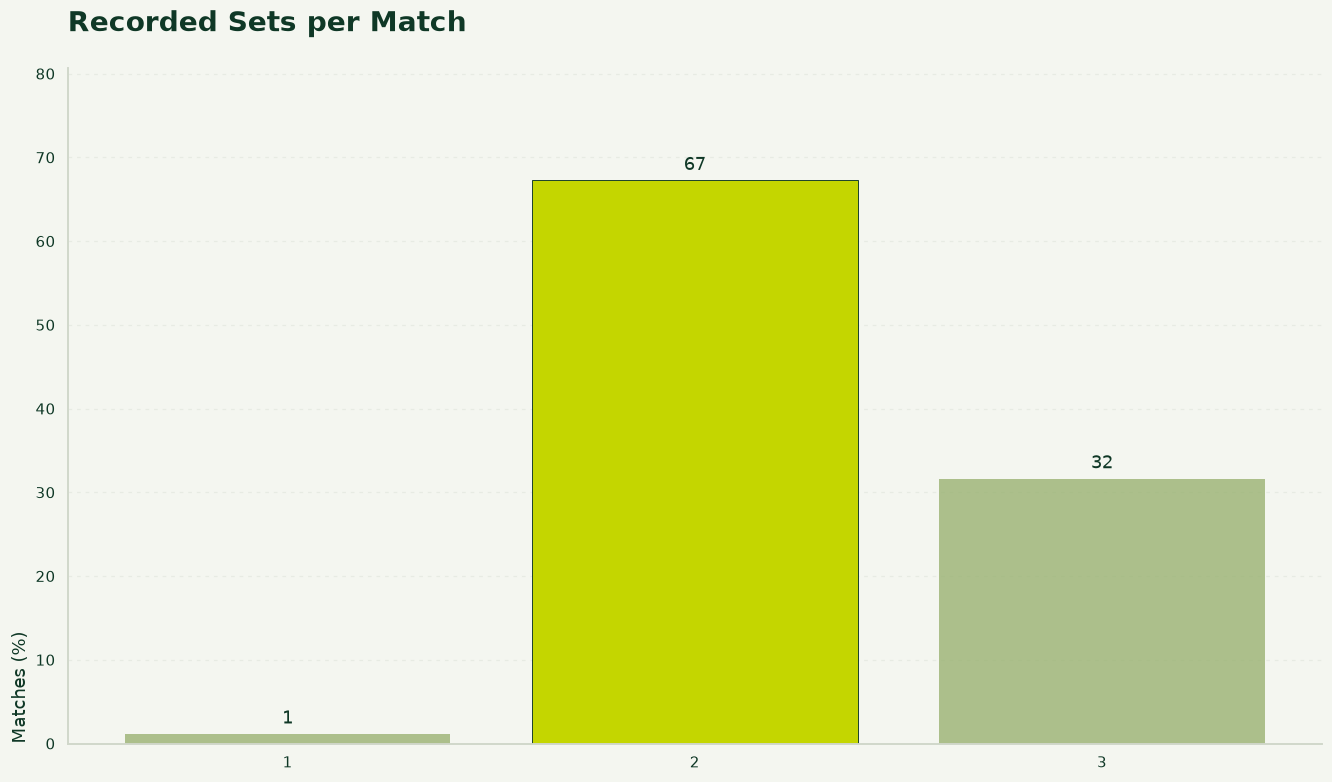

In [14]:
q05_CREAM = '#F4F6F0'
q05_WHITE = '#FFFFFF'
q05_LIME = '#C4D600'
q05_OLIVE = '#5A7263'
q05_GREEN = '#0F3826'
q05_RED = '#C86D51'
q05_GRAY = '#98B06F'
q05_INK = '#0F3826'
q05_fig, q05_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q05_fig.set_facecolor(q05_CREAM)
q05_ax.set_facecolor(q05_WHITE)
q05_shown = q05_r
q05_ax.bar(q05_shown.index.astype(str), q05_shown.values, color=[q05_GREEN if q05_v == q05_shown.max() else q05_GRAY for q05_v in q05_shown])
q05_ax.bar_label(q05_ax.containers[0], fmt='%.0f', padding=4, color=q05_INK)
q05_ax.margins(y=0.2)
for q05_bar in q05_ax.containers[0]:
    q05_bar.set_edgecolor('none')
    q05_bar.set_alpha(0.78)
q05_peak = max((q05_bar.get_width() if 5 in [3,6,9] else q05_bar.get_height()) for q05_bar in q05_ax.containers[0])
for q05_bar in q05_ax.containers[0]:
    if abs((q05_bar.get_width() if 5 in [3,6,9] else q05_bar.get_height()) - q05_peak) < 1e-9:
        q05_bar.set_facecolor(q05_LIME)
        q05_bar.set_edgecolor(q05_GREEN)
        q05_bar.set_linewidth(0.6)
        q05_bar.set_alpha(1)
q05_ax.set_title('Recorded Sets per Match', loc='left', fontsize=18, fontweight='bold', color=q05_INK, pad=24)
q05_ax.set_ylabel('Matches (%)', fontsize=12, color=q05_INK,loc='bottom')
q05_ax.spines[['top', 'right']].set_visible(False)
q05_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q05_ax.tick_params(colors=q05_INK, labelsize=10)
q05_ax.set_axisbelow(True)
q05_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q05_fig.set_facecolor(q05_CREAM)
q05_ax.set_facecolor(q05_WHITE)
q05_ax.patch.set_alpha(0)
sns.despine(ax=q05_ax, top=True, right=True)
q05_ax.tick_params(length=0, pad=8)
q05_fig.savefig(FIG/'q05.svg',bbox_inches='tight',facecolor=q05_CREAM)
q05_fig.savefig(FIG / 'q05.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q05_fig)


بیشترین مسابقات با دو ست ثبت شده‌اند که نشان می‌دهد در بخش بزرگی از مسابقات، برنده 
توانسته هر دو ست اول را پیروز شود و مسابقه بدون نیاز به ست سوم پایان یافته است. مسابقات سه‌سته‌ای حدود یک‌سوم داده را تشکیل می‌دهند و نشان‌دهندهٔ رقابت نزدیک‌تر میان بازیکنان هستند. این نتیجه بر اساس ست‌های ثبت‌شده در داده است 

## 06
## کدام کشور موفق‌ترین بازیکنان را داشته است؟

## Which country has produced the most successful tennis players?

In [15]:
q06_country = long.groupby('country', dropna=False).agg(Wins=('won', 'sum'), Appearances=('won', 'size'), Players=('player_id', 'nunique'))
q06_country['Win_rate_pct'] = q06_country.Wins / q06_country.Appearances * 100
q06_r = q06_country.Wins.sort_values(ascending=False)
q06_answer = q06_r.index[0]
ipy_display(q06_country.sort_values('Wins', ascending=False).head(15))
q06_country.to_csv(OUT / 'country_context.csv', encoding='utf-8-sig')
save_result(6, q06_r)

,Wins,Appearances,Players,Win_rate_pct
country,,,,
France,785,1541,196,50.940947
USA,748,1472,215,50.815217
Italy,626,1306,200,47.932619
Russia,466,910,130,51.208791
Argentina,400,762,92,52.493438
Germany,398,812,118,49.014778
Japan,375,784,117,47.831633
Australia,355,686,87,51.749271
Spain,351,717,92,48.953975


,Wins
country,
France,785
USA,748
Italy,626
Russia,466
Argentina,400
Germany,398
Japan,375
Australia,355
Spain,351


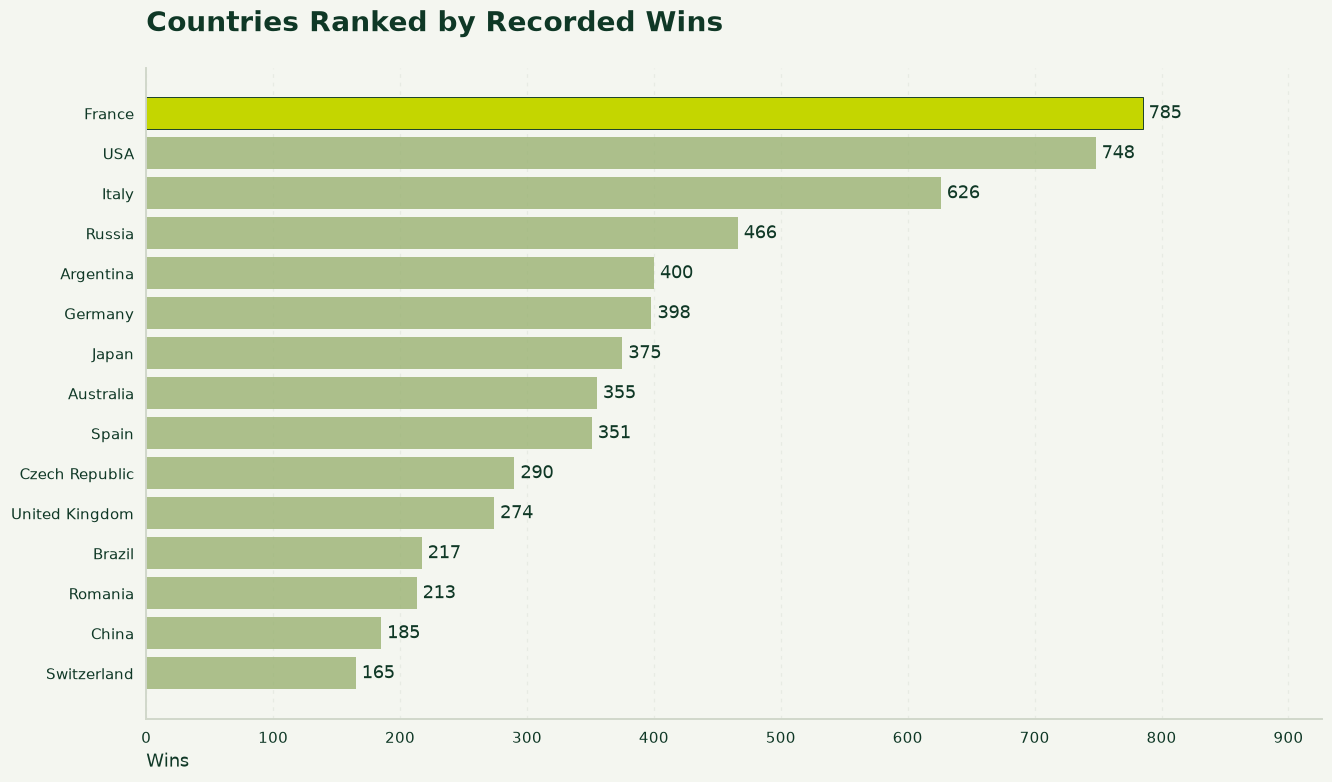

In [16]:
q06_CREAM = '#F4F6F0'
q06_WHITE = '#FFFFFF'
q06_LIME = '#C4D600'
q06_OLIVE = '#5A7263'
q06_GREEN = '#0F3826'
q06_RED = '#C86D51'
q06_GRAY = '#98B06F'
q06_INK = '#0F3826'
q06_fig, q06_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q06_fig.set_facecolor(q06_CREAM)
q06_ax.set_facecolor(q06_WHITE)
q06_shown = q06_r.head(15).sort_values()
q06_colors = [q06_GREEN if q06_v == q06_shown.max() else q06_GRAY for q06_v in q06_shown]
q06_ax.barh(q06_shown.index.astype(str), q06_shown.values, color=q06_colors)
q06_ax.bar_label(q06_ax.containers[0], fmt='%.0f', padding=4, color=q06_INK)
q06_ax.margins(x=0.18)
for q06_bar in q06_ax.containers[0]:
    q06_bar.set_edgecolor('none')
    q06_bar.set_alpha(0.78)
q06_peak = max((q06_bar.get_width() if 6 in [3,6,9] else q06_bar.get_height()) for q06_bar in q06_ax.containers[0])
for q06_bar in q06_ax.containers[0]:
    if abs((q06_bar.get_width() if 6 in [3,6,9] else q06_bar.get_height()) - q06_peak) < 1e-9:
        q06_bar.set_facecolor(q06_LIME)
        q06_bar.set_edgecolor(q06_GREEN)
        q06_bar.set_linewidth(0.6)
        q06_bar.set_alpha(1)
q06_ax.set_title('Countries Ranked by Recorded Wins', loc='left', fontsize=18, fontweight='bold', color=q06_INK, pad=24)
q06_ax.set_xlabel('Wins', fontsize=12, color=q06_INK,loc='left')
q06_ax.spines[['top', 'right']].set_visible(False)
q06_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q06_ax.tick_params(colors=q06_INK, labelsize=10)
q06_ax.set_axisbelow(True)
q06_ax.grid(axis='x', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q06_fig.set_facecolor(q06_CREAM)
q06_ax.set_facecolor(q06_WHITE)
q06_ax.patch.set_alpha(0)
sns.despine(ax=q06_ax, top=True, right=True)
q06_ax.tick_params(length=0, pad=8)
q06_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
q06_fig.savefig(FIG/'q06.svg',bbox_inches='tight',facecolor=q06_CREAM)
q06_fig.savefig(FIG / 'q06.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q06_fig)

 **پاسخ محاسبه‌شده: France**
 
 France با 785 برد صدرنشین بیشترین برد است، اما نرخ بردش 50.94٪ در 1,541 حضور است. بنابراین رتبه اول مجموع برد را نباید برتری قاطع در احتمال برد تعبیر کرد؛ برای مقایسه کشورها این دو شاخص باید هم‌زمان دیده شوند.

## 07
## میانگین تعداد ایس در هر مسابقه چقدر است؟

## What is the average number of aces per match?

In [17]:
q07_r = pair_total('aces').dropna()
q07_answer = q07_r.mean()
print('Mean total aces per match:', q07_answer, 'n:', len(q07_r))
save_result(7, q07_r)

Mean total aces per match: 5.780757666867108 n: 8315


,0
match_id,
11998445,18.0
11998446,9.0
11998447,12.0
11998448,4.0
11998449,10.0
11998450,26.0
11998451,12.0
11998456,18.0
11998459,7.0


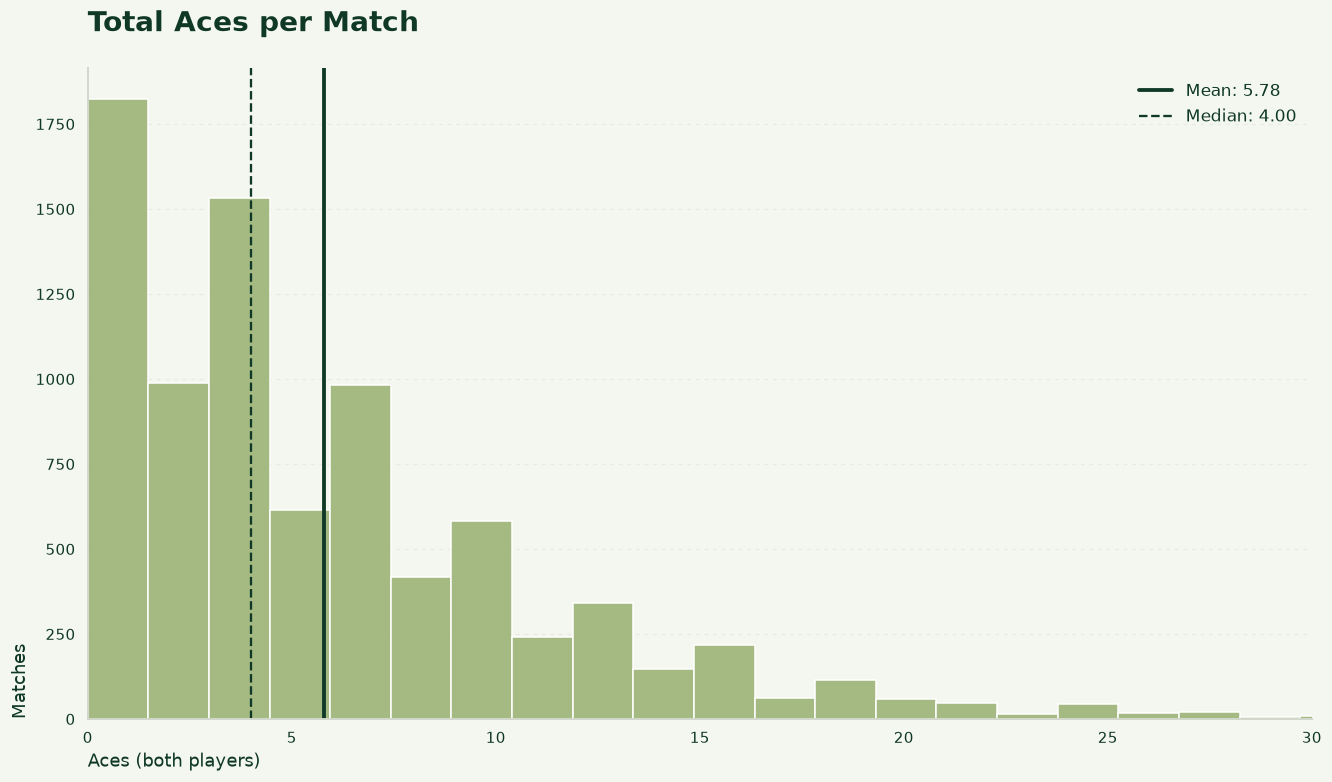

In [18]:
q07_CREAM = '#F4F6F0'
q07_WHITE = '#FFFFFF'
q07_LIME = '#C4D600'
q07_OLIVE = '#5A7263'
q07_GREEN = '#0F3826'
q07_RED = '#C86D51'
q07_GRAY = '#98B06F'
q07_INK = '#0F3826'
q07_fig, q07_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q07_fig.set_facecolor(q07_CREAM)
q07_ax.set_facecolor(q07_WHITE)
q07_values = pd.to_numeric(q07_r, errors='coerce').dropna()
sns.histplot(x=q07_values, bins=35, color=q07_GRAY, edgecolor='white', alpha=0.85, ax=q07_ax)
q07_ax.set_xlim(0, 30)
q07_ax.set_xticks(np.arange(0, 31, 5))
q07_ax.axvline(q07_values.mean(), color=q07_GREEN, lw=2.5, label=f'Mean: {q07_values.mean():.2f}')
q07_ax.axvline(q07_values.median(), color=q07_INK, lw=1.5, ls='--', label=f'Median: {q07_values.median():.2f}')
q07_ax.legend(frameon=False)
q07_ax.set_ylabel('Matches' if True else 'Players',loc= 'bottom' )
q07_ax.set_title('Total Aces per Match', loc='left', fontsize=18, fontweight='bold', color=q07_INK, pad=24)
q07_ax.set_xlabel('Aces (both players)', fontsize=12, color=q07_INK,loc='left')
q07_ax.spines[['top', 'right']].set_visible(False)
q07_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q07_ax.tick_params(colors=q07_INK, labelsize=10)
q07_ax.set_axisbelow(True)
q07_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q07_fig.set_facecolor(q07_CREAM)
q07_ax.set_facecolor(q07_WHITE)
q07_ax.patch.set_alpha(0)
sns.despine(ax=q07_ax, top=True, right=True)
q07_ax.tick_params(length=0, pad=8)
q07_fig.savefig(FIG/'q07.svg',bbox_inches='tight',facecolor=q07_CREAM)
q07_fig.savefig(FIG / 'q07.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q07_fig)

پاسخ محاسبه‌شده: 5.78

میانگین تعداد ایس در هر مسابقه حدود ۵٫۷۸ است. این مقدار نشان می‌دهد که به‌طور متوسط در هر مسابقه نزدیک به شش امتیاز مستقیم از سرویس ثبت شده است. مقدار ایس به عواملی مانند جنسیت، قد، قدرت سرویس، سطح زمین و سبک بازی وابسته است؛ بنابراین تحلیل جداگانه بر اساس جنسیت یا سطح زمین می‌تواند تفاوت‌های مهم‌تری را آشکار کند.

## 08
## آیا تعداد خطاهای دوبل بین زنان و مردان تفاوت دارد؟

## Is there a difference in the number of double faults based on gender?

In [19]:
q08_f = pair_total('double_faults')
q08_g = matches.set_index('match_id').gender
q08_box = pd.DataFrame({'value': q08_f, 'group': q08_g}).dropna()
q08_r = q08_box.groupby('group').value.agg(['mean', 'median', 'count'])
q08_answer = q08_r['mean'].to_dict()
save_result(8, q08_r)

,mean,median,count
group,,,
F,6.989396,6.0,3678
M,5.312541,5.0,4617
Unknown,6.650000,5.0,20


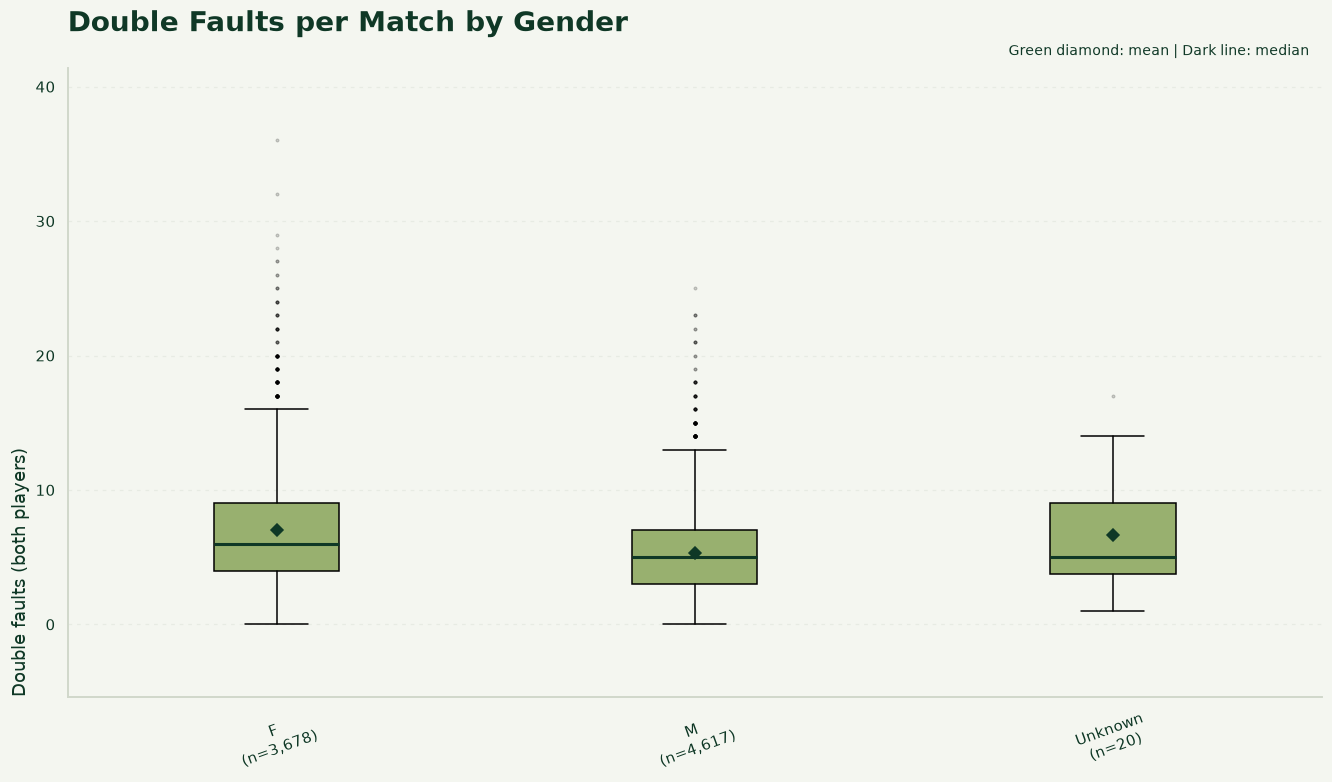

In [20]:
q08_CREAM = '#F4F6F0'
q08_WHITE = '#FFFFFF'
q08_LIME = '#C4D600'
q08_OLIVE = '#5A7263'
q08_GREEN = '#0F3826'
q08_RED = '#C86D51'
q08_GRAY = '#98B06F'
q08_INK = '#0F3826'
q08_fig, q08_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q08_fig.set_facecolor(q08_CREAM)
q08_ax.set_facecolor(q08_WHITE)
q08_groups = list(q08_r.index)
q08_values = [q08_box.loc[q08_box.group.eq(q08_g), 'value'].dropna() for q08_g in q08_groups]
q08_bp = q08_ax.boxplot(q08_values, tick_labels=[f'{q08_g}\n(n={len(q08_v):,})' for q08_g, q08_v in zip(q08_groups, q08_values)], patch_artist=True, showmeans=True, meanprops={'marker': 'D', 'markerfacecolor': q08_GREEN, 'markeredgecolor': q08_GREEN}, medianprops={'color': q08_INK, 'linewidth': 2}, flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.25})
for q08_patch in q08_bp['boxes']:
    q08_patch.set_facecolor(q08_GRAY)
q08_ax.tick_params(axis='x', labelrotation=20)
q08_ax.margins(y=0.15)
q08_ax.text(0.99, 1.015, 'Green diamond: mean | Dark line: median', transform=q08_ax.transAxes, ha='right', va='bottom', fontsize=9, color=q08_INK)
q08_ax.set_title('Double Faults per Match by Gender', loc='left', fontsize=18, fontweight='bold', color=q08_INK, pad=24)
q08_ax.set_ylabel('Double faults (both players)', fontsize=12, color=q08_INK,loc= 'bottom')
q08_ax.spines[['top', 'right']].set_visible(False)
q08_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q08_ax.tick_params(colors=q08_INK, labelsize=10)
q08_ax.set_axisbelow(True)
q08_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q08_fig.set_facecolor(q08_CREAM)
q08_ax.set_facecolor(q08_WHITE)
q08_ax.patch.set_alpha(0)
sns.despine(ax=q08_ax, top=True, right=True)
q08_ax.tick_params(length=0, pad=8)
q08_fig.savefig(FIG/'q08.svg',bbox_inches='tight',facecolor=q08_CREAM)
q08_fig.savefig(FIG / 'q08.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q08_fig)

**پاسخ محاسبه‌شده: {'F': 6.989396411092986, 'M': 5.3125406107862245, 'Unknown': 6.65}**

میانگین خطاهای دوبل برای زنان حدود ۶٫۹۹ و برای مردان حدود ۵٫۳۱ در هر مسابقه است. بنابراین زنان در این دیتاست به‌طور متوسط حدود ۱٫۶۸ خطای دوبل بیشتر داشته‌اند. این اختلاف می‌تواند به تفاوت در سبک سرویس، سرعت بازی، نوع مسابقات و ترکیب داده مربوط باشد؛ بنابراین بدون آزمون آماری و کنترل عوامل زمینه‌ای، نمی‌توان آن را به تفاوت قطعی جنسیتی نسبت داد.

## 09
## کدام بازیکن در یک ماه بیشترین تورنمنت را برده است؟

## Which player has won the most tournaments in a single month?

In [21]:
q09_finals = matches.loc[matches.round_name.astype(str).str.lower().eq('final')].copy()
q09_finals['winner_id'] = q09_finals.h_player_id.where(q09_finals.winner_code.eq(1), q09_finals.a_player_id)
q09_finals['month'] = q09_finals.date.dt.strftime('%Y-%m')
q09_keys = ['tour_tournament_id', 'season_season_id', 'gender', 'month']
if q09_finals.duplicated(q09_keys).any():
    raise ValueError('Ambiguous repeated finals require inspection')
q09_counts = q09_finals.groupby(['winner_id', 'month']).size().sort_values(ascending=False)
q09_answer = q09_counts.max()
q09_r = q09_counts.copy()
q09_r.index = [f'{names.get(q09_p, q09_p)} | {q09_month}' for q09_p, q09_month in q09_r.index]
print('Maximum:', q09_answer, 'Joint leaders:', q09_r[q09_r.eq(q09_answer)].to_dict())
q09_finals.to_csv(OUT / 'finals_evidence.csv', index=False, encoding='utf-8-sig')
save_result(9, q09_r)

Maximum: 3 Joint leaders: {'Popko D. | 2024-02': 3, 'Nicod J. | 2024-03': 3, 'Jianu F. | 2024-03': 3, 'Gengel M. | 2024-02': 3}


,0
Popko D. | 2024-02,3
Nicod J. | 2024-03,3
Jianu F. | 2024-03,3
Gengel M. | 2024-02,3
Jakupović D. | 2024-03,2
Dellien Velasco M. | 2024-02,2
Kwiatkowski T. | 2024-03,2
Helgo M. | 2024-03,2
Kužmová K. | 2024-02,2
Boisson L. | 2024-03,2


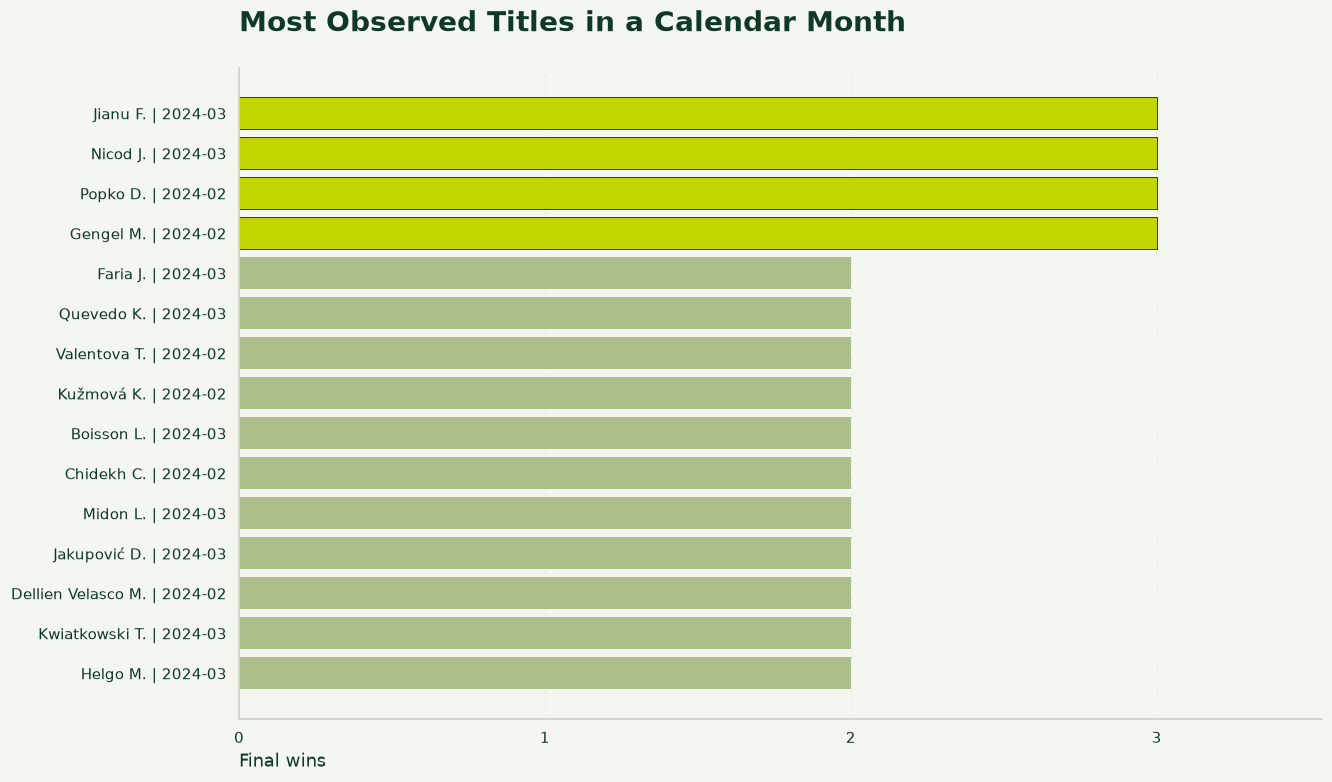

In [22]:
q09_CREAM = '#F4F6F0'
q09_WHITE = '#FFFFFF'
q09_LIME = '#C4D600'
q09_OLIVE = '#5A7263'
q09_GREEN = '#0F3826'
q09_RED = '#C86D51'
q09_GRAY = '#98B06F'
q09_INK = '#0F3826'
q09_fig, q09_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q09_fig.set_facecolor(q09_CREAM)
q09_ax.set_facecolor(q09_WHITE)
q09_shown = q09_r.head(15).sort_values()
q09_colors = [q09_GREEN if q09_v == q09_shown.max() else q09_GRAY for q09_v in q09_shown]
q09_ax.barh(q09_shown.index.astype(str), q09_shown.values, color=q09_colors)
q09_ax.margins(x=0.18)
for q09_bar in q09_ax.containers[0]:
    q09_bar.set_edgecolor('none')
    q09_bar.set_alpha(0.78)
q09_peak = max((q09_bar.get_width() if 9 in [3,6,9] else q09_bar.get_height()) for q09_bar in q09_ax.containers[0])
for q09_bar in q09_ax.containers[0]:
    if abs((q09_bar.get_width() if 9 in [3,6,9] else q09_bar.get_height()) - q09_peak) < 1e-9:
        q09_bar.set_facecolor(q09_LIME)
        q09_bar.set_edgecolor(q09_GREEN)
        q09_bar.set_linewidth(0.6)
        q09_bar.set_alpha(1)
q09_ax.set_title('Most Observed Titles in a Calendar Month', loc='left', fontsize=18, fontweight='bold', color=q09_INK, pad=24)
q09_ax.set_xlabel('Final wins', fontsize=12, color=q09_INK,loc='left')
q09_ax.spines[['top', 'right']].set_visible(False)
q09_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q09_ax.tick_params(colors=q09_INK, labelsize=10)
q09_ax.set_axisbelow(True)
q09_ax.grid(axis='x', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q09_fig.set_facecolor(q09_CREAM)
q09_ax.set_facecolor(q09_WHITE)
q09_ax.patch.set_alpha(0)
sns.despine(ax=q09_ax, top=True, right=True)
q09_ax.tick_params(length=0, pad=8)
q09_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
q09_fig.savefig(FIG/'q09.svg',bbox_inches='tight',facecolor=q09_CREAM)
q09_fig.savefig(FIG / 'q09.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q09_fig)

بیشترین تعداد قهرمانی ثبت‌شده در یک ماه برابر با ۳ عنوان است. این رکورد به‌صورت مشترک در اختیار Jianu F.، Nicod J.، Popko D. و Gengel M. قرار دارد. این بازیکنان در ماه‌های مختلف سال ۲۰۲۴ توانسته‌اند در سه مسابقهٔ فینال پیروز شوند؛ بنابراین هیچ بازیکنی به‌تنهایی برتری مطلق ندارد و نتیجه به‌صورت مشترک ثبت شده است



## 10
## قد و رتبه بازیکن چه همبستگی‌ای دارند؟

## Is there a correlation between a player’s height and their ranking?

In [23]:
q10_scatter = players[['height_cm', 'rank', 'gender']].dropna()
q10_r = q10_scatter.groupby('gender').apply(lambda f: pd.Series({'n': len(f), 'Pearson': f.height_cm.corr(f['rank']), 'Spearman': f.height_cm.rank().corr(f['rank'].rank())}), include_groups=False)
q10_answer = q10_scatter.height_cm.corr(q10_scatter['rank'])
print('Pooled Pearson:', q10_answer)
save_result(10, q10_r)

Pooled Pearson: 0.10456192101080711


,n,Pearson,Spearman
gender,,,
F,252.0,-0.190926,-0.226599
M,1081.0,-0.112867,-0.121142


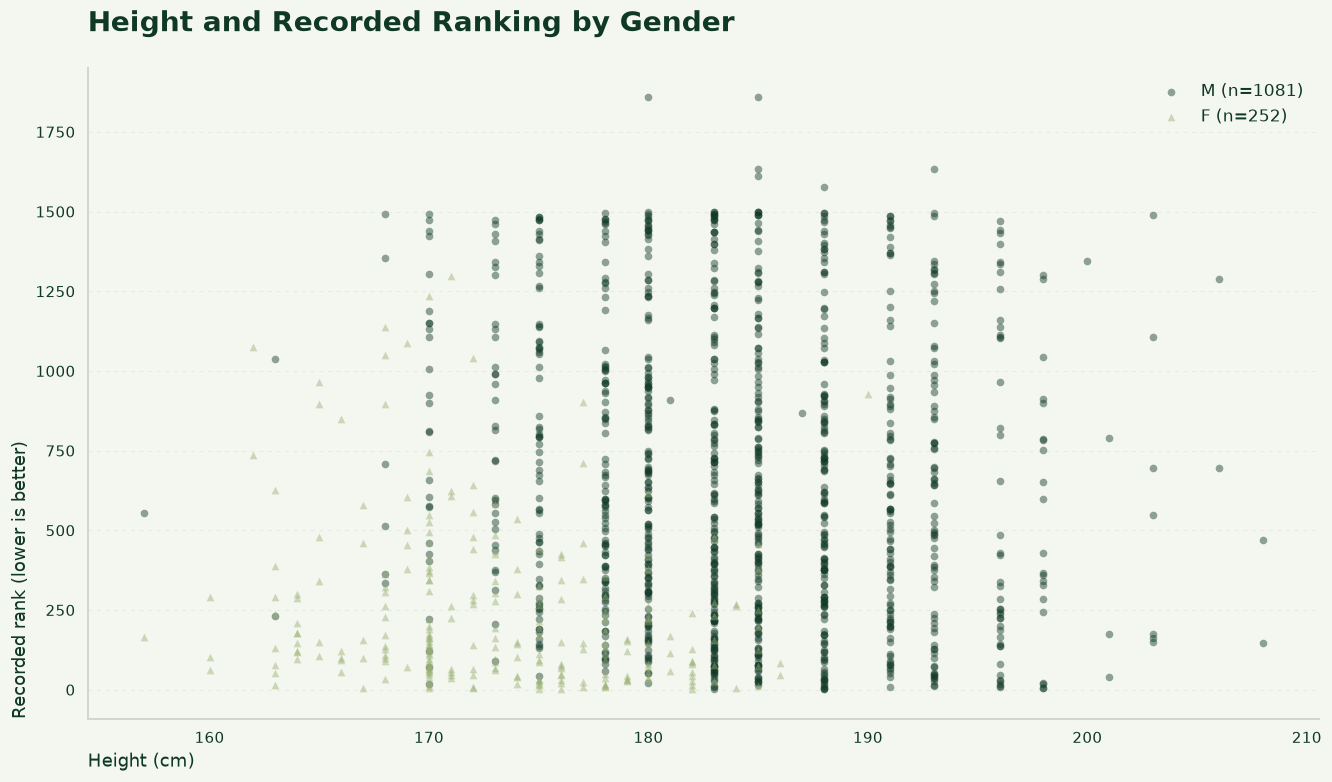

In [24]:
q10_CREAM = '#F4F6F0'
q10_WHITE = '#FFFFFF'
q10_LIME = '#C4D600'
q10_OLIVE = '#5A7263'
q10_GREEN = '#0F3826'
q10_RED = '#C86D51'
q10_GRAY = '#98B06F'
q10_INK = '#0F3826'
q10_fig, q10_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q10_fig.set_facecolor(q10_CREAM)
q10_ax.set_facecolor(q10_WHITE)
for q10_gender, q10_color, q10_marker in [('M', q10_GREEN, 'o'), ('F', q10_GRAY, '^')]:
    q10_sub = q10_scatter.loc[q10_scatter.gender.eq(q10_gender)]
    sns.scatterplot(data=q10_sub, x='height_cm', y='rank', ax=q10_ax, color=q10_color, marker=q10_marker, alpha=0.45, s=25, linewidth=0, label=f'{q10_gender} (n={len(q10_sub)})')
q10_ax.set_ylabel('Recorded rank (lower is better)',loc= 'bottom')
q10_ax.legend(frameon=False)
q10_ax.set_title('Height and Recorded Ranking by Gender', loc='left', fontsize=18, fontweight='bold', color=q10_INK, pad=24)
q10_ax.set_xlabel('Height (cm)', fontsize=12, color=q10_INK,loc='left')
q10_ax.spines[['top', 'right']].set_visible(False)
q10_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q10_ax.tick_params(colors=q10_INK, labelsize=10)
q10_ax.set_axisbelow(True)
q10_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q10_fig.set_facecolor(q10_CREAM)
q10_ax.set_facecolor(q10_WHITE)
q10_ax.patch.set_alpha(0)
sns.despine(ax=q10_ax, top=True, right=True)
q10_ax.tick_params(length=0, pad=8)
q10_fig.savefig(FIG/'q10.svg',bbox_inches='tight',facecolor=q10_CREAM)
q10_fig.savefig(FIG / 'q10.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q10_fig)


همبستگی کلی بین قد بازیکن و رتبه برابر با ۰٫۱۰۵ است؛ بنابراین رابطهٔ خطی کلی بسیار 
ضعیف است و نمی‌توان گفت قد به‌تنهایی عامل تعیین‌کنندهٔ رتبهٔ بازیکن است.
بااین‌حال، وقتی داده‌ها بر اساس جنسیت بررسی می‌شوند، همبستگی برای زنان حدود ۰٫۱۹- و برای مردان حدود ۰٫۱۱- به دست می‌آید. از آنجا که در رتبه‌بندی تنیس عدد کمتر نشان‌دهندهٔ رتبهٔ بهتر است، این همبستگی منفی می‌تواند نشان دهد که در داخل هر گروه، بازیکنان بلندقدتر اندکی رتبهٔ بهتری دارند؛ اما شدت این رابطه همچنان ضعیف است.
تفاوت بین همبستگی کلی و همبستگی‌های جداگانه نشان می‌دهد که ترکیب جنسیتی و ساختار داده بر نتیجه اثر گذاشته است. در نتیجه، قد به‌تنهایی معیار مناسبی برای پیش‌بینی رتبه نیست و عواملی مانند مهارت فنی، تجربه، آمادگی بدنی، سطح مسابقات و عملکرد بازیکن نقش مهم‌تری دارند.

## 11
## میانگین مدت مسابقات چقدر است؟

## What is the average duration of matches?

In [25]:
q11_r = matches.loc[matches.duration_complete, 'duration_hours'].dropna()
q11_answer = q11_r.mean()
print('Mean hours:', q11_answer, 'Median hours:', q11_r.median(), 'n:', len(q11_r), 'Above 7h:', q11_r.gt(7).sum())
save_result(11, q11_r)

Mean hours: 1.9924262849537608 Median hours: 1.6705555555555556 n: 8098 Above 7h: 72


,duration_hours
2,2.805556
3,1.350833
4,1.570556
5,1.591389
6,1.168889
7,2.341111
8,1.993333
9,2.114444
10,1.439167
11,2.063611


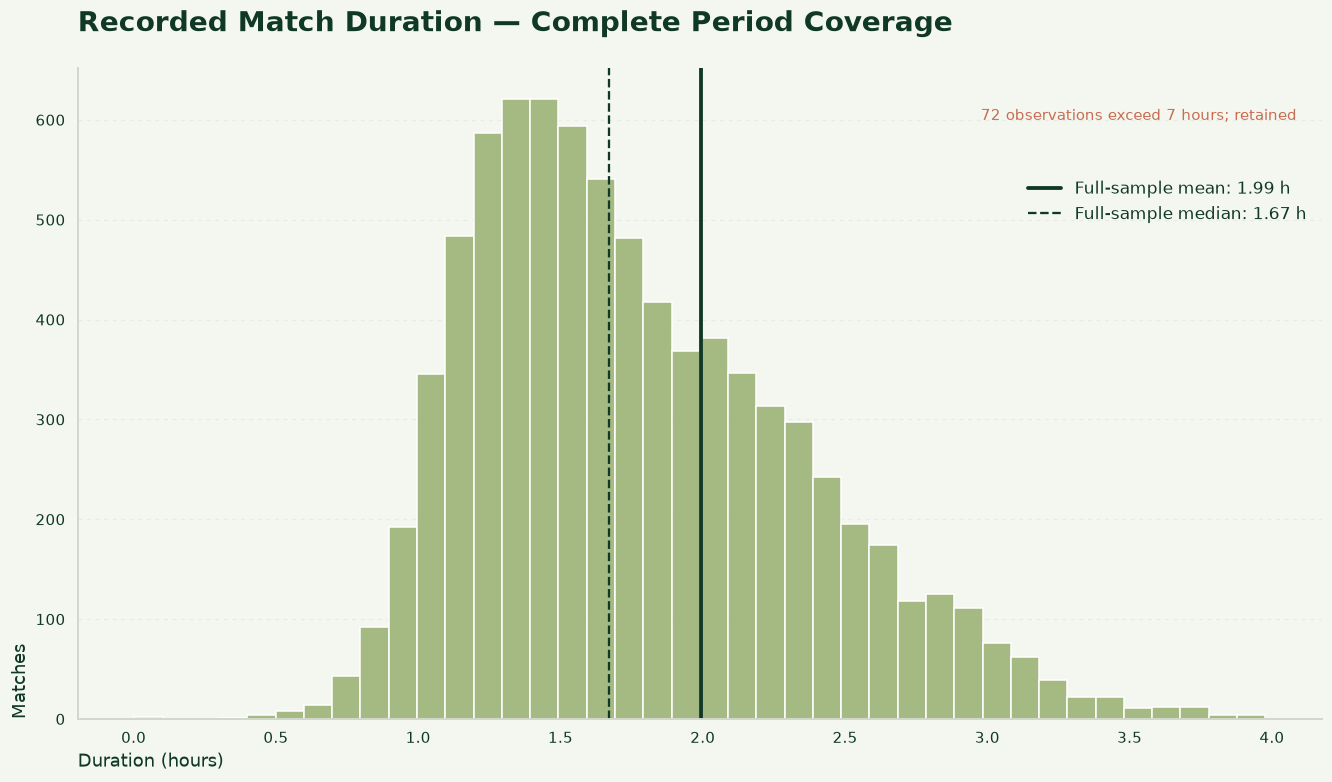

In [26]:
q11_CREAM = '#F4F6F0'
q11_WHITE = '#FFFFFF'
q11_LIME = '#C4D600'
q11_OLIVE = '#5A7263'
q11_GREEN = '#0F3826'
q11_RED = '#C86D51'
q11_GRAY = '#98B06F'
q11_INK = '#0F3826'
q11_fig, q11_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q11_fig.set_facecolor(q11_CREAM)
q11_ax.set_facecolor(q11_WHITE)
q11_values = pd.to_numeric(q11_r, errors='coerce').dropna()
q11_central = q11_values.loc[q11_values.le(4)]
sns.histplot(x=q11_central, bins=40, color=q11_GRAY, edgecolor='white', alpha=0.85, ax=q11_ax)
q11_ax.axvline(q11_values.mean(), color=q11_GREEN, lw=2.5, label=f'Full-sample mean: {q11_values.mean():.2f} h')
q11_ax.axvline(q11_values.median(), color=q11_INK, ls='--', label=f'Full-sample median: {q11_values.median():.2f} h')
q11_ax.set_ylabel('Matches',loc= 'bottom')
q11_ax.legend(frameon=False, loc='upper right', bbox_to_anchor=(1, 0.85))
q11_ax.text(0.98, 0.92, f'{q11_values.gt(7).sum():,} observations exceed 7 hours; retained', transform=q11_ax.transAxes, ha='right', color=q11_RED, fontsize=10)
q11_ax.set_title('Recorded Match Duration — Complete Period Coverage', loc='left', fontsize=18, fontweight='bold', color=q11_INK, pad=24)
q11_ax.set_xlabel('Duration (hours)', fontsize=12, color=q11_INK,loc='left')
q11_ax.spines[['top', 'right']].set_visible(False)
q11_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q11_ax.tick_params(colors=q11_INK, labelsize=10)
q11_ax.set_axisbelow(True)
q11_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q11_fig.set_facecolor(q11_CREAM)
q11_ax.set_facecolor(q11_WHITE)
q11_ax.patch.set_alpha(0)
sns.despine(ax=q11_ax, top=True, right=True)
q11_ax.tick_params(length=0, pad=8)
q11_fig.savefig(FIG/'q11.svg',bbox_inches='tight',facecolor=q11_CREAM)
q11_fig.savefig(FIG / 'q11.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q11_fig)

**پاسخ محاسبه‌شده: ۱۱۹٫۶۷ دقیقه** 

میانگین مدت مسابقات کامل و دارای زمان معتبر برابر با ۱٫۹۹ ساعت، یعنی حدود ۱۱۹٫۵ دقیقه است. میانهٔ مدت مسابقات ۱٫۶۷ ساعت، معادل تقریباً ۱۰۰ دقیقه، به دست آمده است.
بالاتر بودن میانگین از میانه نشان می‌دهد که توزیع زمان مسابقات کاملاً متقارن نیست و چند مسابقهٔ بسیار طولانی میانگین را افزایش داده‌اند. در مجموع ۸٬۰۹۸ مسابقه برای این محاسبه دارای زمان معتبر بوده‌اند و ۷۲ رکورد بالاتر از ۷ ساعت به‌عنوان مقادیر غیرعادی علامت‌گذاری شده‌اند.
بنابراین میانه، تصویر واقع‌بینانه‌تری از زمان معمول مسابقات ارائه می‌دهد؛ یعنی یک مسابقهٔ معمولی در این داده حدود ۱۰۰ دقیقه طول می‌کشد، در حالی که میانگین تحت تأثیر مسابقات بسیار طولانی به حدود ۱۲۰ دقیقه رسیده است.

## 12
## میانگین گیم در هر ست برای زنان و مردان چه تفاوتی دارد؟

## What is the average number of games per set in men’s matches compared to women’s matches?

In [27]:
q12_records = []
for q12_j in range(5):
    for q12_gender in ['M', 'F']:
        q12_mask = complete[:, q12_j] & matches.gender.eq(q12_gender).to_numpy()
        q12_records.extend(({'group': q12_gender, 'value': q12_v} for q12_v in (score_h[:, q12_j] + score_a[:, q12_j])[q12_mask]))
q12_box = pd.DataFrame(q12_records)
q12_r = q12_box.groupby('group').value.agg(['mean', 'median', 'count'])
q12_answer = q12_r['mean'].to_dict()
save_result(12, q12_r)

,mean,median,count
group,,,
F,9.170726,9.0,8294
M,9.545689,9.0,10484


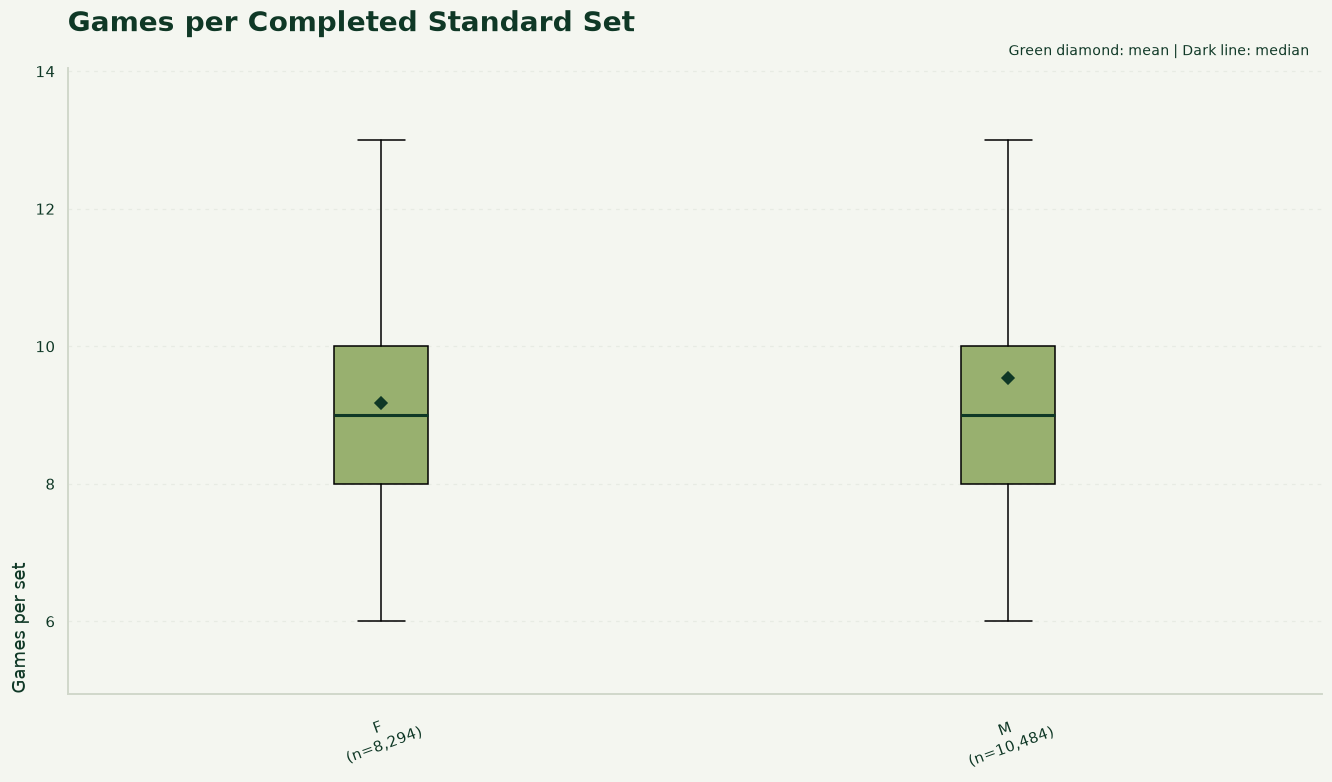

In [28]:
q12_CREAM = '#F4F6F0'
q12_WHITE = '#FFFFFF'
q12_LIME = '#C4D600'
q12_OLIVE = '#5A7263'
q12_GREEN = '#0F3826'
q12_RED = '#C86D51'
q12_GRAY = '#98B06F'
q12_INK = '#0F3826'
q12_fig, q12_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q12_fig.set_facecolor(q12_CREAM)
q12_ax.set_facecolor(q12_WHITE)
q12_groups = list(q12_r.index)
q12_values = [q12_box.loc[q12_box.group.eq(q12_g), 'value'].dropna() for q12_g in q12_groups]
q12_bp = q12_ax.boxplot(q12_values, tick_labels=[f'{q12_g}\n(n={len(q12_v):,})' for q12_g, q12_v in zip(q12_groups, q12_values)], patch_artist=True, showmeans=True, meanprops={'marker': 'D', 'markerfacecolor': q12_GREEN, 'markeredgecolor': q12_GREEN}, medianprops={'color': q12_INK, 'linewidth': 2}, flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.25})
for q12_patch in q12_bp['boxes']:
    q12_patch.set_facecolor(q12_GRAY)
q12_ax.tick_params(axis='x', labelrotation=20)
q12_ax.margins(y=0.15)
q12_ax.text(0.99, 1.015, 'Green diamond: mean | Dark line: median', transform=q12_ax.transAxes, ha='right', va='bottom', fontsize=9, color=q12_INK)
q12_ax.set_title('Games per Completed Standard Set', loc='left', fontsize=18, fontweight='bold', color=q12_INK, pad=24)
q12_ax.set_ylabel('Games per set', fontsize=12, color=q12_INK,loc= 'bottom')
q12_ax.spines[['top', 'right']].set_visible(False)
q12_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q12_ax.tick_params(colors=q12_INK, labelsize=10)
q12_ax.set_axisbelow(True)
q12_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q12_fig.set_facecolor(q12_CREAM)
q12_ax.set_facecolor(q12_WHITE)
q12_ax.patch.set_alpha(0)
sns.despine(ax=q12_ax, top=True, right=True)
q12_ax.tick_params(length=0, pad=8)
q12_fig.savefig(FIG/'q12.svg',bbox_inches='tight',facecolor=q12_CREAM)
q12_fig.savefig(FIG / 'q12.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q12_fig)

**پاسخ محاسبه‌شده: {'F': 9.17072582589824, 'M': 9.545688668447157}**

میانگین تعداد گیم در هر ست برای مسابقات زنان حدود ۹٫۱۸ گیم و برای مسابقات مردان حدود ۹٫۵۶ گیم است. بنابراین ست‌های مسابقات مردان به‌طور متوسط حدود ۰٫۳۸ گیم طولانی‌تر هستند.
این اختلاف نشان می‌دهد که ست‌های مردان در این داده کمی رقابتی‌تر یا طولانی‌تر بوده‌اند، اما فاصلهٔ میانگین‌ها زیاد نیست و نباید آن را یک تفاوت بسیار بزرگ در نظر گرفت. محاسبه فقط بر اساس ست‌های کامل و دارای امتیاز معتبر انجام شده و ست‌های ناقص یا الگوهای نامعتبر حذف شده‌اند.

## 13
## توزیع بازیکنان چپ‌دست و راست‌دست چگونه است؟

## What is the distribution of left-handed versus right-handed players?

In [29]:
q13_r = players.plays.fillna('Unknown').value_counts()
q13_answer = q13_r.to_dict()
print('Counts:', q13_answer)
print('Percent of all profiles:', (q13_r / len(players) * 100).round(2).to_dict())
save_result(13, q13_r)

Counts: {'Unknown': 1498, 'right-handed': 1013, 'left-handed': 133}
Percent of all profiles: {'Unknown': 56.66, 'right-handed': 38.31, 'left-handed': 5.03}


,count
plays,
Unknown,1498
right-handed,1013
left-handed,133


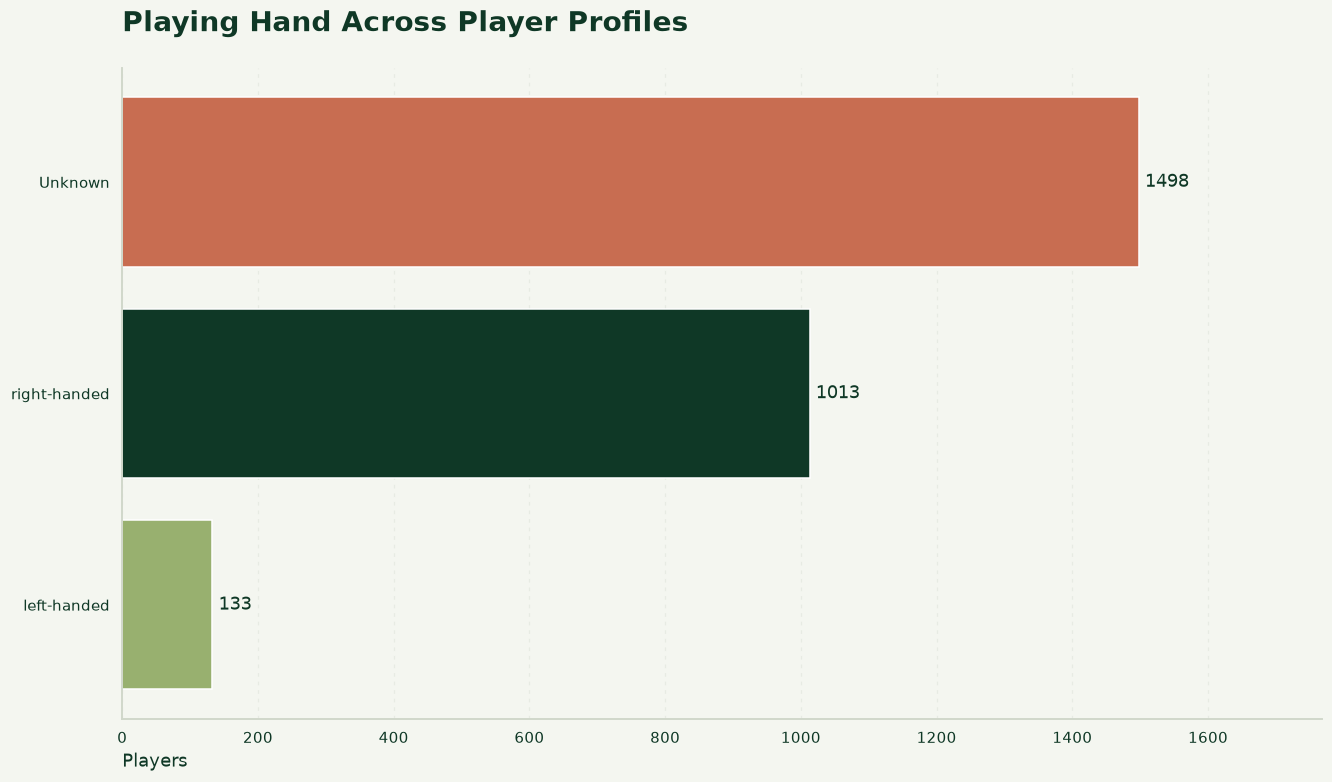

In [30]:
q13_CREAM = '#F4F6F0'
q13_WHITE = '#FFFFFF'
q13_LIME = '#C4D600'
q13_OLIVE = '#5A7263'
q13_GREEN = '#0F3826'
q13_RED = '#C86D51'
q13_GRAY = '#98B06F'
q13_INK = '#0F3826'
q13_fig, q13_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q13_fig.set_facecolor(q13_CREAM)
q13_ax.set_facecolor(q13_WHITE)
q13_shown = q13_r.head(15).sort_values()
q13_colors = [q13_GREEN if q13_v == q13_shown.max() else q13_GRAY for q13_v in q13_shown]
q13_ax.barh(q13_shown.index.astype(str), q13_shown.values, color=q13_colors)
q13_ax.bar_label(q13_ax.containers[0], fmt='%.0f', padding=4, color=q13_INK)
q13_ax.margins(x=0.18)
for q13_patch, q13_label in zip(q13_ax.patches, q13_shown.index):
    q13_patch.set_facecolor(q13_RED if q13_label == 'Unknown' else q13_GREEN if q13_label == 'right-handed' else q13_GRAY)
q13_ax.set_title('Playing Hand Across Player Profiles', loc='left', fontsize=18, fontweight='bold', color=q13_INK, pad=24)
q13_ax.set_xlabel('Players', fontsize=12, color=q13_INK,loc='left')
q13_ax.spines[['top', 'right']].set_visible(False)
q13_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q13_ax.tick_params(colors=q13_INK, labelsize=10)
q13_ax.set_axisbelow(True)
q13_ax.grid(axis='x', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q13_fig.set_facecolor(q13_CREAM)
q13_ax.set_facecolor(q13_WHITE)
q13_ax.patch.set_alpha(0)
sns.despine(ax=q13_ax, top=True, right=True)
q13_ax.tick_params(length=0, pad=8)
q13_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
q13_fig.savefig(FIG/'q13.svg',bbox_inches='tight',facecolor=q13_CREAM)
q13_fig.savefig(FIG / 'q13.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q13_fig)

بیشتر بازیکنان ثبت‌شده راست‌دست هستند: ۱٬۰۱۳ نفر. تعداد بازیکنان چپ‌دست ۱۳۳ نفر و تعداد بازیکنانی که وضعیت دست آن‌ها مشخص نیست ۱٬۴۹۸ نفر است. بنابراین به‌دلیل حجم زیاد داده‌های نامشخص، نمی‌توان نسبت چپ‌دست و راست‌دست را نمایندهٔ کل بازیکنان دانست.

## 14
## رایج‌ترین سطح زمین تورنمنت‌ها چیست؟

## What is the most common type of surface used in tournaments?

In [31]:
q14_t = matches[['tour_tournament_id', 'gender', 'tour_ground_type']].drop_duplicates()
if q14_t.duplicated(['tour_tournament_id', 'gender']).any():
    print('Warning: some tournament IDs have multiple surface labels; count is tournament-surface pairs')
q14_r = q14_t.tour_ground_type.fillna('Unknown').value_counts()
q14_answer = q14_r.index[0]
save_result(14, q14_r)

,count
tour_ground_type,
Hardcourt outdoor,230
Red clay,175
Hardcourt indoor,87
Red clay indoor,9
Carpet indoor,5
Synthetic outdoor,4
Grass,4
Unknown,2
Green clay,1


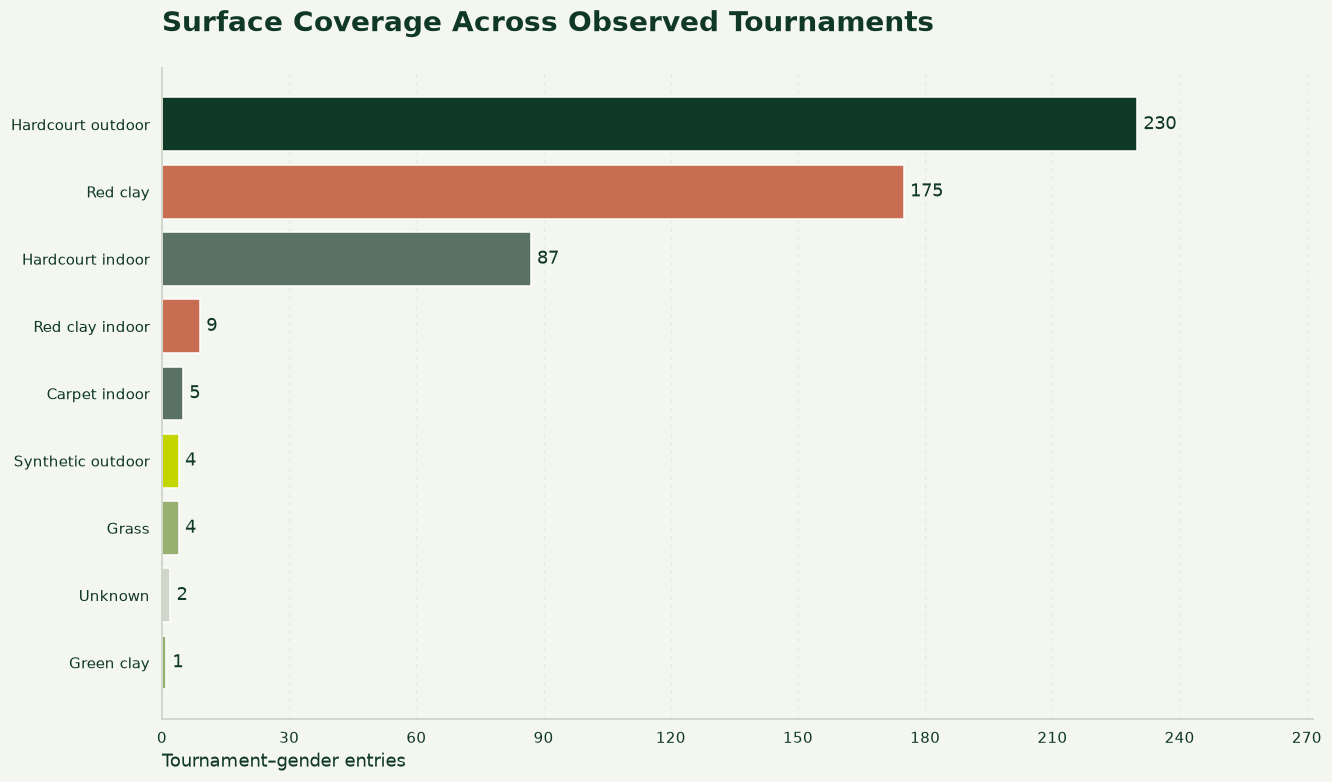

In [32]:
q14_CREAM = '#F4F6F0'
q14_WHITE = '#FFFFFF'
q14_LIME = '#C4D600'
q14_OLIVE = '#5A7263'
q14_GREEN = '#0F3826'
q14_RED = '#C86D51'
q14_GRAY = '#98B06F'
q14_INK = '#0F3826'
q14_fig, q14_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q14_fig.set_facecolor(q14_CREAM)
q14_ax.set_facecolor(q14_WHITE)
q14_shown = q14_r.head(15).sort_values()
q14_colors = [q14_GREEN if q14_v == q14_shown.max() else q14_GRAY for q14_v in q14_shown]
q14_ax.barh(q14_shown.index.astype(str), q14_shown.values, color=q14_colors)
q14_ax.bar_label(q14_ax.containers[0], fmt='%.0f', padding=4, color=q14_INK)
q14_ax.margins(x=0.18)
q14_surface_palette = {'Hardcourt outdoor':'#0F3826','Hardcourt indoor':'#5A7263','Red clay':'#C86D51',
    'Red clay indoor':'#C86D51','Green clay':'#98B06F','Grass':'#98B06F',
    'Carpet indoor':'#5A7263','Synthetic outdoor':'#C4D600','Unknown':'#D0D7CA'}
for q14_bar, q14_label in zip(q14_ax.containers[0], q14_shown.index):
    q14_bar.set_facecolor(q14_surface_palette.get(q14_label, '#98B06F'))
q14_ax.set_title('Surface Coverage Across Observed Tournaments', loc='left', fontsize=18, fontweight='bold', color=q14_INK, pad=24)
q14_ax.set_xlabel('Tournament–gender entries', fontsize=12, color=q14_INK,loc='left')
q14_ax.spines[['top', 'right']].set_visible(False)
q14_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q14_ax.tick_params(colors=q14_INK, labelsize=10)
q14_ax.set_axisbelow(True)
q14_ax.grid(axis='x', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q14_fig.set_facecolor(q14_CREAM)
q14_ax.set_facecolor(q14_WHITE)
q14_ax.patch.set_alpha(0)
sns.despine(ax=q14_ax, top=True, right=True)
q14_ax.tick_params(length=0, pad=8)
q14_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
q14_fig.savefig(FIG/'q14.svg',bbox_inches='tight',facecolor=q14_CREAM)
q14_fig.savefig(FIG / 'q14.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q14_fig)

**پاسخ محاسبه‌شده: Hardcourt outdoor**

یج‌ترین سطح زمین در داده‌ها Hardcourt outdoor با ۲۳۰ تورنمنت است. پس از آن، زمین خاک رس قرمز با ۱۷۵ تورنمنت قرار دارد. این نتیجه نشان می‌دهد که مسابقات فضای باز روی زمین سخت سهم بیشتری از داده را تشکیل می‌دهند؛ اما این موضوع الزاماً به معنای محبوب‌تر بودن این سطح در کل دنیای تنیس نیست، زیرا به پوشش دیتاست وابسته است.

## 15
## چند کشور متمایز در داده حضور دارند؟

## How many distinct countries are represented in the dataset?

In [33]:
q15_pc = set(players.country.dropna().astype(str).str.strip()) - set([''])
q15_vc = set(tables['venue'].country.dropna().astype(str).str.strip()) - set([''])
q15_r = pd.Series({'Player countries': len(q15_pc), 'Venue countries': len(q15_vc), 'Union': len(q15_pc | q15_vc)})
q15_answer = len(q15_pc)
print('Primary answer (player countries):', q15_answer)
save_result(15, q15_r)

Primary answer (player countries): 101


,0
Player countries,101
Venue countries,64
Union,108


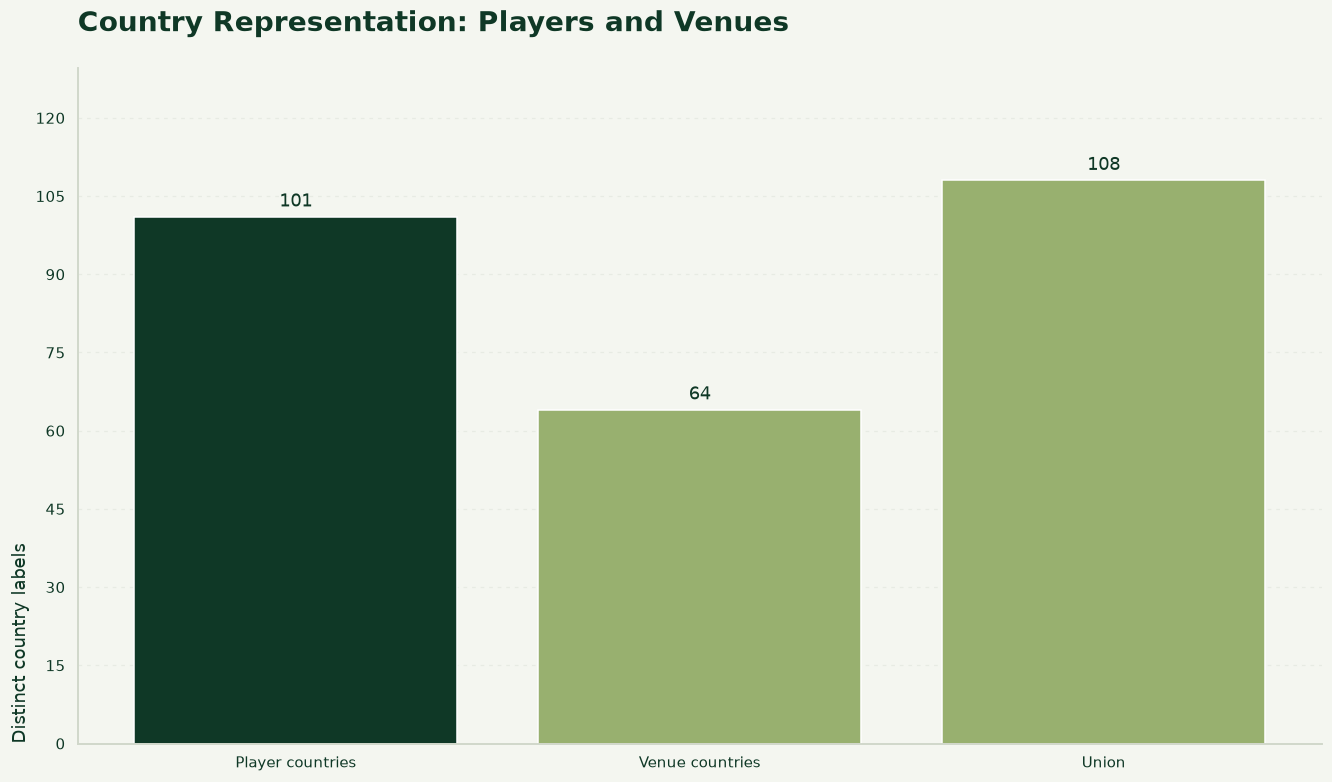

In [34]:
q15_CREAM = '#F4F6F0'
q15_WHITE = '#FFFFFF'
q15_LIME = '#C4D600'
q15_OLIVE = '#5A7263'
q15_GREEN = '#0F3826'
q15_RED = '#C86D51'
q15_GRAY = '#98B06F'
q15_INK = '#0F3826'
q15_fig, q15_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q15_fig.set_facecolor(q15_CREAM)
q15_ax.set_facecolor(q15_WHITE)
q15_shown = q15_r
q15_ax.bar(q15_shown.index.astype(str), q15_shown.values, color=[q15_GREEN if q15_v == q15_shown.max() else q15_GRAY for q15_v in q15_shown])
q15_ax.bar_label(q15_ax.containers[0], fmt='%.0f', padding=4, color=q15_INK)
q15_ax.margins(y=0.2)
for q15_patch, q15_label in zip(q15_ax.patches, q15_shown.index):
    q15_patch.set_facecolor(q15_GREEN if q15_label == 'Player countries' else q15_GRAY)
q15_ax.set_title('Country Representation: Players and Venues', loc='left', fontsize=18, fontweight='bold', color=q15_INK, pad=24)
q15_ax.set_ylabel('Distinct country labels', fontsize=12, color=q15_INK,loc= 'bottom')
q15_ax.spines[['top', 'right']].set_visible(False)
q15_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q15_ax.tick_params(colors=q15_INK, labelsize=10)
q15_ax.set_axisbelow(True)
q15_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q15_fig.set_facecolor(q15_CREAM)
q15_ax.set_facecolor(q15_WHITE)
q15_ax.patch.set_alpha(0)
sns.despine(ax=q15_ax, top=True, right=True)
q15_ax.tick_params(length=0, pad=8)
q15_ax.yaxis.set_major_locator(MaxNLocator(integer=True))
q15_fig.savefig(FIG/'q15.svg',bbox_inches='tight',facecolor=q15_CREAM)
q15_fig.savefig(FIG / 'q15.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q15_fig)

**پاسخ محاسبه‌شده: 101**

در اطلاعات بازیکنان، ۱۰۱ کشور متمایز حضور دارند و در اطلاعات محل برگزاری مسابقات، ۶۴ کشور ثبت شده است. اتحاد این دو منبع به ۱۰۸ کشور متمایز می‌رسد. اختلاف بین کشور بازیکن و کشور محل برگزاری نشان می‌دهد که دیتاست هم تنوع بین‌المللی بازیکنان و هم گستردگی جغرافیایی مسابقات را پوشش می‌دهد.

## 16
## بالاترین درصد برد مقابل حریفان دارای رتبه ده نفر اول متعلق به کیست؟

## Which player has the highest winning percentage against top 10 ranked opponents?

In [35]:
q16_top = long.loc[long.opponent_rank.between(1, 10)]
q16_top_table = q16_top.groupby('player_id').won.agg(['sum', 'count'])
q16_top_table['rate'] = q16_top_table['sum'] / q16_top_table['count'] * 100
q16_top_table['name'] = q16_top_table.index.map(names)
q16_top_table = q16_top_table.sort_values(['rate', 'count'], ascending=False)
q16_answer = q16_top_table.rate.max()
ipy_display(q16_top_table.loc[q16_top_table.rate.eq(q16_answer)])
q16_r = q16_top_table.head(15).set_index('name').rate
q16_top_table.to_csv(OUT / 'top10_complete.csv', encoding='utf-8-sig')
save_result(16, q16_r)

,sum,count,rate,name
player_id,,,,
185388.0,3,3,100.0,Humbert U.
228272.0,3,3,100.0,Świątek I.
19578.0,1,1,100.0,Kerber A.
36067.0,1,1,100.0,Tsurenko L.
47603.0,1,1,100.0,Monteiro T.
50641.0,1,1,100.0,Vekić D.
59702.0,1,1,100.0,Haddad Maia B.
64580.0,1,1,100.0,Ćorić B.
69208.0,1,1,100.0,Paolini J.


,rate
name,
Humbert U.,100.0
Świątek I.,100.0
Kerber A.,100.0
Tsurenko L.,100.0
Monteiro T.,100.0
Vekić D.,100.0
Haddad Maia B.,100.0
Ćorić B.,100.0
Paolini J.,100.0


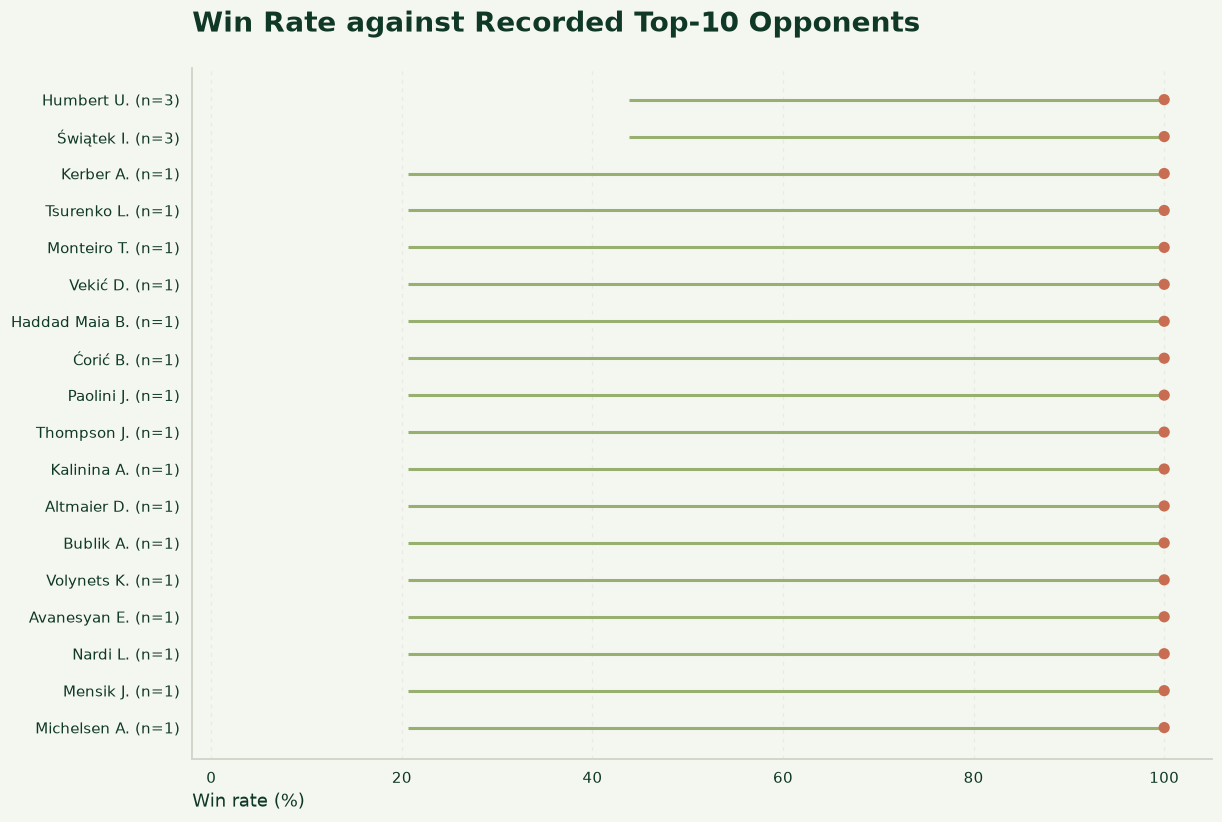

In [36]:
q16_CREAM = '#F4F6F0'
q16_WHITE = '#FFFFFF'
q16_LIME = '#C4D600'
q16_OLIVE = '#5A7263'
q16_GREEN = '#0F3826'
q16_RED = '#C86D51'
q16_GRAY = '#98B06F'
q16_INK = '#0F3826'
q16_fig, q16_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q16_fig.set_facecolor(q16_CREAM)
q16_ax.set_facecolor(q16_WHITE)
q16_shown = q16_top_table.loc[q16_top_table.rate.eq(q16_top_table.rate.max())].iloc[::-1].copy()
q16_fig.set_size_inches(11, max(6, len(q16_shown) * 0.32 + 1.6))
q16_p = q16_shown['sum'] / q16_shown['count']
q16_n_ = q16_shown['count']
q16_z = 1.96
q16_center = (q16_p + q16_z * q16_z / (2 * q16_n_)) / (1 + q16_z * q16_z / q16_n_)
q16_half = q16_z * np.sqrt(q16_p * (1 - q16_p) / q16_n_ + q16_z * q16_z / (4 * q16_n_ * q16_n_)) / (1 + q16_z * q16_z / q16_n_)
q16_y = np.arange(len(q16_shown))
q16_ax.hlines(q16_y, (q16_center - q16_half) * 100, (q16_center + q16_half) * 100, color=q16_GRAY, lw=2)
q16_ax.scatter(q16_shown.rate, q16_y, color=[q16_RED if q16_n < 5 else q16_GREEN for q16_n in q16_n_], zorder=3, s=40)
q16_ax.set_yticks(q16_y, labels=[f"{q16_row['name']} (n={q16_row['count']})" for q16__, q16_row in q16_shown.iterrows()])
q16_ax.set_xlim(-2, 105)
q16_ax.set_title('Win Rate against Recorded Top-10 Opponents', loc='left', fontsize=18, fontweight='bold', color=q16_INK, pad=24)
q16_ax.set_xlabel('Win rate (%)', fontsize=12, color=q16_INK,loc='left')
q16_ax.spines[['top', 'right']].set_visible(False)
q16_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q16_ax.tick_params(colors=q16_INK, labelsize=10)
q16_ax.set_axisbelow(True)
q16_ax.grid(axis='x', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q16_fig.set_facecolor(q16_CREAM)
q16_ax.set_facecolor(q16_WHITE)
q16_ax.patch.set_alpha(0)
sns.despine(ax=q16_ax, top=True, right=True)
q16_ax.tick_params(length=0, pad=8)
q16_fig.savefig(FIG/'q16.svg',bbox_inches='tight',facecolor=q16_CREAM)
q16_fig.savefig(FIG / 'q16.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q16_fig)

چند بازیکن از جمله Humbert U.، Świątek I. و Kerber A. نرخ برد ۱۰۰٪ مقابل حریفان Top 10 داشته‌اند. این نتیجه به معنی برتری قطعی آن‌ها نیست، زیرا نرخ ۱۰۰٪ ممکن است بر اساس تعداد بسیار کمی مسابقه به‌دست آمده باشد. بنابراین برای ارزیابی منصفانه باید حداقل تعداد مسابقات و حجم نمونه نیز گزارش شود.

## 17
## میانگین بریک سرویس در هر مسابقه چقدر است؟

## What is the average number of breaks of serve per match?

In [37]:
q17_r = pair_total('break_points_converted').dropna()
q17_answer = q17_r.mean()
print('Mean breaks per match:', q17_answer, 'n:', len(q17_r))
save_result(17, q17_r)

Mean breaks per match: 6.57939656208679 n: 8319


,0
match_id,
11998445,9.0
11998446,6.0
11998447,4.0
11998448,6.0
11998449,3.0
11998450,4.0
11998451,3.0
11998456,7.0
11998459,5.0


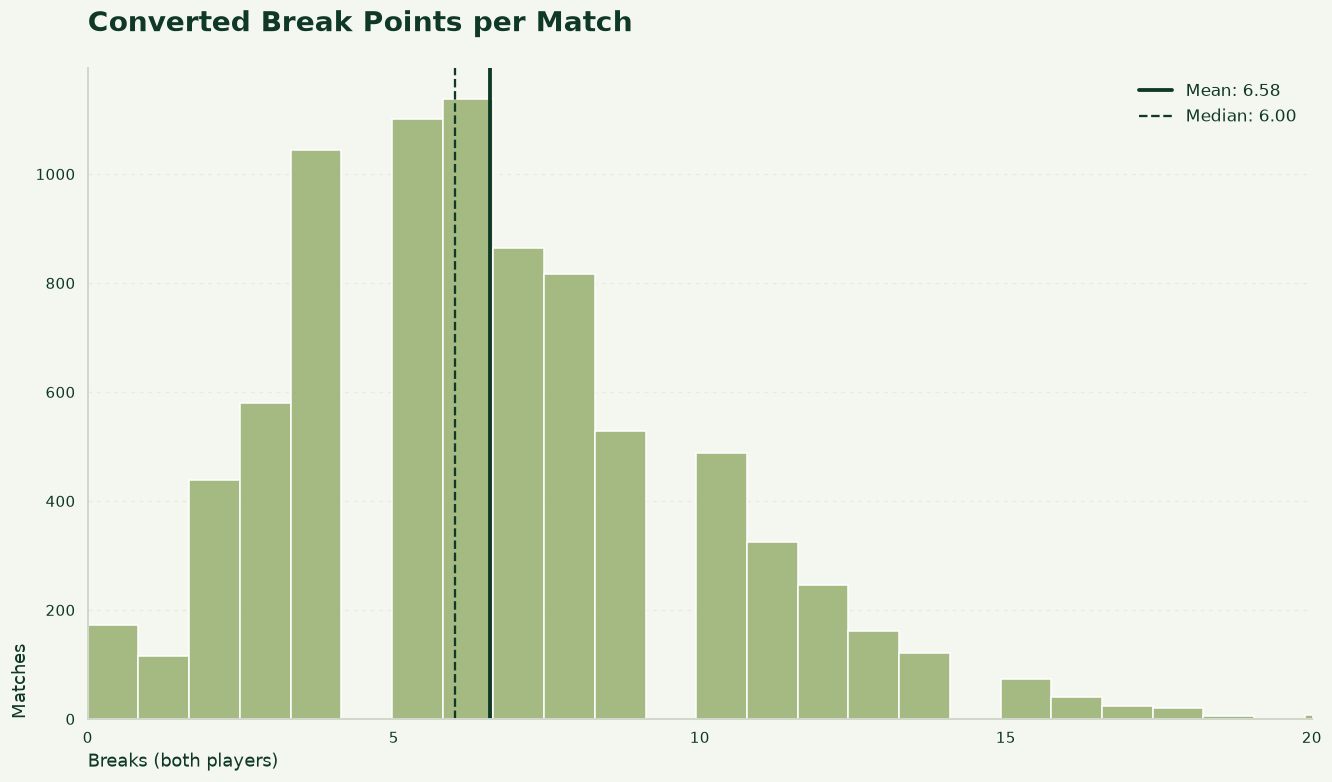

In [38]:
q17_CREAM = '#F4F6F0'
q17_WHITE = '#FFFFFF'
q17_LIME = '#C4D600'
q17_OLIVE = '#5A7263'
q17_GREEN = '#0F3826'
q17_RED = '#C86D51'
q17_GRAY = '#98B06F'
q17_INK = '#0F3826'
q17_fig, q17_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q17_fig.set_facecolor(q17_CREAM)
q17_ax.set_facecolor(q17_WHITE)
q17_values = pd.to_numeric(q17_r, errors='coerce').dropna()
sns.histplot(x=q17_values, bins=35, color=q17_GRAY, edgecolor='white', alpha=0.85, ax=q17_ax)

q17_ax.axvline(q17_values.mean(), color=q17_GREEN, lw=2.5, label=f'Mean: {q17_values.mean():.2f}')
q17_ax.axvline(q17_values.median(), color=q17_INK, lw=1.5, ls='--', label=f'Median: {q17_values.median():.2f}')
q17_ax.legend(frameon=False)
q17_ax.set_ylabel('Matches' if True else 'Players',loc= 'bottom')
q17_ax.set_title('Converted Break Points per Match', loc='left', fontsize=18, fontweight='bold', color=q17_INK, pad=24)
q17_ax.set_xlabel('Breaks (both players)', fontsize=12, color=q17_INK,loc='left')
q17_ax.spines[['top', 'right']].set_visible(False)
q17_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q17_ax.tick_params(colors=q17_INK, labelsize=10)
q17_ax.set_axisbelow(True)
q17_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q17_fig.set_facecolor(q17_CREAM)
q17_ax.set_facecolor(q17_WHITE)
q17_ax.patch.set_alpha(0)
sns.despine(ax=q17_ax, top=True, right=True)
q17_ax.tick_params(length=0, pad=8)
q17_ax.set_xlim(left=0, right=20)
q17_ax.set_xticks(range(0, 21, 5))
q17_fig.savefig(FIG/'q17.svg',bbox_inches='tight',facecolor=q17_CREAM)
q17_fig.savefig(FIG / 'q17.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q17_fig)

**پاسخ محاسبه‌شده: 6.58**

میانگین بریک سرویس در هر مسابقه حدود ۶٫۵۸ است. این مقدار نشان می‌دهد که شکستن سرویس بخش مهمی از جریان مسابقات بوده است. بااین‌حال، میانگین به‌تنهایی تفاوت سطح بازیکنان، جنسیت، سطح زمین و نوع تورنمنت را نشان نمی‌دهد و بهتر است در گروه‌های مختلف نیز مقایسه شود.

## Part 2

## 18
## آیا احتمال برد نهاییِ برنده ست اول بین زنان و مردان متفاوت است؟

## Does the first-set winner’s match-win rate differ by gender?

In [39]:
q18_eligible = matches.loc[complete[:, 0] & matches.gender.isin(['M', 'F']).to_numpy()].copy()
q18_eligible['first_winner'] = np.where(q18_eligible.hs_period_1 > q18_eligible.as_period_1, 1, 2)
q18_eligible['held'] = q18_eligible.first_winner.eq(q18_eligible.winner_code)
q18_summary = q18_eligible.groupby('gender').held.agg(['sum', 'count', 'mean'])
q18_r = q18_summary['mean'] * 100
q18_answer = q18_r.to_dict()
ipy_display(q18_summary)
q18_summary.to_csv(OUT / 'first_set_gender_context.csv', encoding='utf-8-sig')
save_result(18, q18_r)

,sum,count,mean
gender,,,
F,3016,3664,0.823144
M,3828,4630,0.826782


,mean
gender,
F,82.314410
M,82.678186


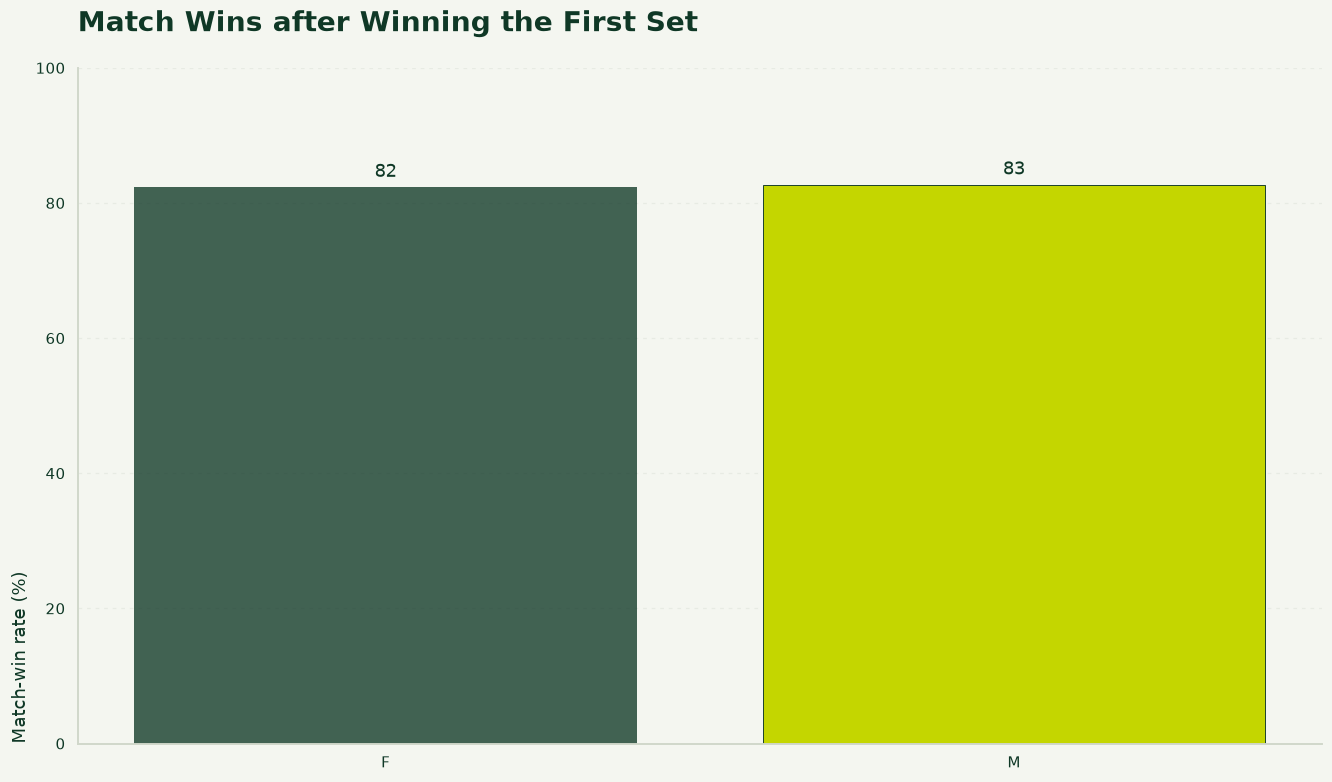

In [40]:
q18_CREAM = '#F4F6F0'
q18_WHITE = '#FFFFFF'
q18_LIME = '#C4D600'
q18_OLIVE = '#5A7263'
q18_GREEN = '#0F3826'
q18_RED = '#C86D51'
q18_GRAY = '#98B06F'
q18_INK = '#0F3826'
q18_fig, q18_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q18_fig.set_facecolor(q18_CREAM)
q18_ax.set_facecolor(q18_WHITE)
q18_shown = q18_r
q18_ax.bar(q18_shown.index.astype(str), q18_shown.values, color=[q18_GREEN if q18_v == q18_shown.max() else q18_GRAY for q18_v in q18_shown])
q18_ax.bar_label(q18_ax.containers[0], fmt='%.0f', padding=4, color=q18_INK)
q18_ax.margins(y=0.2)
for q18_patch in q18_ax.patches:
    q18_patch.set_facecolor(q18_GREEN)
q18_ax.set_ylim(0, 100)
for q18_bar in q18_ax.containers[0]:
    q18_bar.set_edgecolor('none')
    q18_bar.set_alpha(0.78)
q18_peak = max((q18_bar.get_width() if 18 in [3,6,9] else q18_bar.get_height()) for q18_bar in q18_ax.containers[0])
for q18_bar in q18_ax.containers[0]:
    if abs((q18_bar.get_width() if 18 in [3,6,9] else q18_bar.get_height()) - q18_peak) < 1e-9:
        q18_bar.set_facecolor(q18_LIME)
        q18_bar.set_edgecolor(q18_GREEN)
        q18_bar.set_linewidth(0.6)
        q18_bar.set_alpha(1)
q18_ax.set_title('Match Wins after Winning the First Set', loc='left', fontsize=18, fontweight='bold', color=q18_INK, pad=24)
q18_ax.set_ylabel('Match-win rate (%)', fontsize=12, color=q18_INK,loc= 'bottom')
q18_ax.spines[['top', 'right']].set_visible(False)
q18_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q18_ax.tick_params(colors=q18_INK, labelsize=10)
q18_ax.set_axisbelow(True)
q18_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q18_fig.set_facecolor(q18_CREAM)
q18_ax.set_facecolor(q18_WHITE)
q18_ax.patch.set_alpha(0)
sns.despine(ax=q18_ax, top=True, right=True)
q18_ax.tick_params(length=0, pad=8)
q18_fig.savefig(FIG/'q18.svg',bbox_inches='tight',facecolor=q18_CREAM)
q18_fig.savefig(FIG / 'q18.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q18_fig)

**پاسخ محاسبه‌شده: {'F': 82.31441048034934, 'M': 82.67818574514038}**

رخ برد مسابقه پس از پیروزی در ست اول برای زنان ۸۲٫۳۱٪ و برای مردان ۸۲٫۶۸٪ است. اختلاف فقط حدود ۰٫۳۶ واحد درصد است؛ بنابراین در این دیتاست تفاوت معنادار و قابل‌توجهی بین زنان و مردان مشاهده نمی‌شود. در هر دو گروه، بردن ست اول با احتمال بالای پیروزی نهایی همراه است.

## 19
## درصد امتیازگیری از سرویس دوم بین برندگان و بازندگان چه تفاوتی دارد؟

## How does second-serve points-won percentage differ between winners and losers?

In [41]:
q19_f = stat('second_serve_points')
q19_records = []
q19_invalid_rates = 0
for q19_side, q19_code_ in [('home', 1), ('away', 2)]:
    q19_value = q19_f[q19_side + '_value']
    q19_total = q19_f[q19_side + '_total']
    q19_valid = q19_value.ge(0) & q19_value.le(q19_total) & q19_total.gt(0)
    q19_invalid_rates += int((q19_value.notna() & q19_total.notna() & ((q19_value < 0) | (q19_value > q19_total))).sum())
    q19_rate = q19_value / q19_total.where(q19_valid) * 100
    q19_records.extend(({'group': 'Winner' if q19_win else 'Loser', 'value': q19_val} for q19_val, q19_win in zip(q19_rate, matches.winner_code.eq(q19_code_)) if pd.notna(q19_val)))
q19_box = pd.DataFrame(q19_records)
q19_r = q19_box.groupby('group').value.agg(['mean', 'median', 'count'])
q19_answer = q19_r['mean'].to_dict()
print('Impossible source rates excluded:', q19_invalid_rates)
assert q19_box.value.between(0, 100).all()
save_result(19, q19_r)

Impossible source rates excluded: 62


,mean,median,count
group,,,
Loser,40.707613,41.379310,8297
Winner,52.529794,52.631579,8253


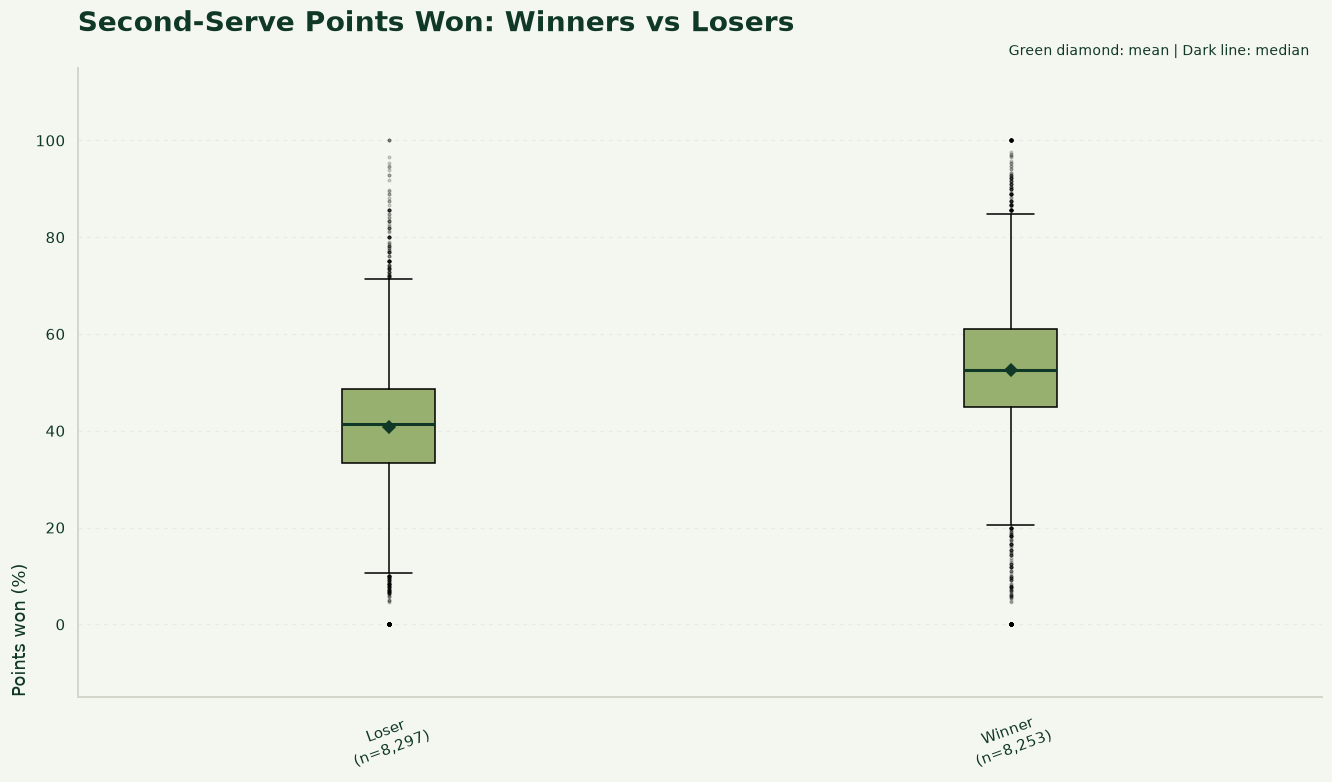

In [42]:
q19_CREAM = '#F4F6F0'
q19_WHITE = '#FFFFFF'
q19_LIME = '#C4D600'
q19_OLIVE = '#5A7263'
q19_GREEN = '#0F3826'
q19_RED = '#C86D51'
q19_GRAY = '#98B06F'
q19_INK = '#0F3826'
q19_fig, q19_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q19_fig.set_facecolor(q19_CREAM)
q19_ax.set_facecolor(q19_WHITE)
q19_groups = list(q19_r.index)
q19_values = [q19_box.loc[q19_box.group.eq(q19_g), 'value'].dropna() for q19_g in q19_groups]
q19_bp = q19_ax.boxplot(q19_values, tick_labels=[f'{q19_g}\n(n={len(q19_v):,})' for q19_g, q19_v in zip(q19_groups, q19_values)], patch_artist=True, showmeans=True, meanprops={'marker': 'D', 'markerfacecolor': q19_GREEN, 'markeredgecolor': q19_GREEN}, medianprops={'color': q19_INK, 'linewidth': 2}, flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.25})
for q19_patch in q19_bp['boxes']:
    q19_patch.set_facecolor(q19_GRAY)
q19_ax.tick_params(axis='x', labelrotation=20)
q19_ax.margins(y=0.15)
q19_ax.text(0.99, 1.015, 'Green diamond: mean | Dark line: median', transform=q19_ax.transAxes, ha='right', va='bottom', fontsize=9, color=q19_INK)
q19_ax.set_title('Second-Serve Points Won: Winners vs Losers', loc='left', fontsize=18, fontweight='bold', color=q19_INK, pad=24)
q19_ax.set_ylabel('Points won (%)', fontsize=12, color=q19_INK,loc= 'bottom')
q19_ax.spines[['top', 'right']].set_visible(False)
q19_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q19_ax.tick_params(colors=q19_INK, labelsize=10)
q19_ax.set_axisbelow(True)
q19_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q19_fig.set_facecolor(q19_CREAM)
q19_ax.set_facecolor(q19_WHITE)
q19_ax.patch.set_alpha(0)

sns.despine(ax=q19_ax, top=True, right=True)
q19_ax.tick_params(length=0, pad=8)
q19_fig.savefig(FIG/'q19.svg',bbox_inches='tight',facecolor=q19_CREAM)
q19_fig.savefig(FIG / 'q19.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q19_fig)

**پاسخ محاسبه‌شده: {'Loser': 40.707612620153135, 'Winner': 52.52979445656788}**

برندگان به‌طور میانگین ۵۲٫۵۳٪ از امتیازهای سرویس دوم خود را برده‌اند، درحالی‌که این مقدار برای بازندگان ۴۰٫۷۱٪ است. اختلاف ۱۱٫۸۲ واحد درصدی نشان می‌دهد که کیفیت بازی روی سرویس دوم یکی از مهم‌ترین عوامل تمایز برنده و بازنده است. بااین‌حال، این رابطه توصیفی است و به‌تنهایی علت قطعی پیروزی را ثابت نمی‌کند.

## 20
## درصد تبدیل فرصت بریک بین برندگان و بازندگان چه تفاوتی دارد؟

## How does break-point conversion differ between winners and losers?

In [43]:
q20_f = stat('break_points_converted')
q20_saved = stat('break_points_saved')
q20_records = []
q20_inconsistent = 0
for q20_side, q20_other, q20_code_ in [('home', 'away', 1), ('away', 'home', 2)]:
    q20_opportunities = q20_saved[q20_other + '_total']
    q20_converted = q20_f[q20_side + '_value']
    q20_expected = q20_opportunities - q20_saved[q20_other + '_value']
    q20_consistent = q20_converted.eq(q20_expected) & q20_converted.ge(0) & q20_converted.le(q20_opportunities)
    q20_inconsistent += int((q20_converted.notna() & q20_expected.notna() & ~q20_consistent).sum())
    q20_rate = q20_converted / q20_opportunities.where(q20_opportunities.gt(0) & q20_consistent) * 100
    q20_records.extend(({'group': 'Winner' if q20_win else 'Loser', 'value': q20_val} for q20_val, q20_win in zip(q20_rate, matches.winner_code.eq(q20_code_)) if pd.notna(q20_val)))
q20_box = pd.DataFrame(q20_records)
q20_r = q20_box.groupby('group').value.agg(['mean', 'median', 'count'])
q20_answer = q20_r['mean'].to_dict()
print('Inconsistent player-match records excluded from rate calculation:', q20_inconsistent)
save_result(20, q20_r)

Inconsistent player-match records excluded from rate calculation: 1144


,mean,median,count
group,,,
Loser,38.946899,36.363636,7238
Winner,53.446385,50.000000,7699


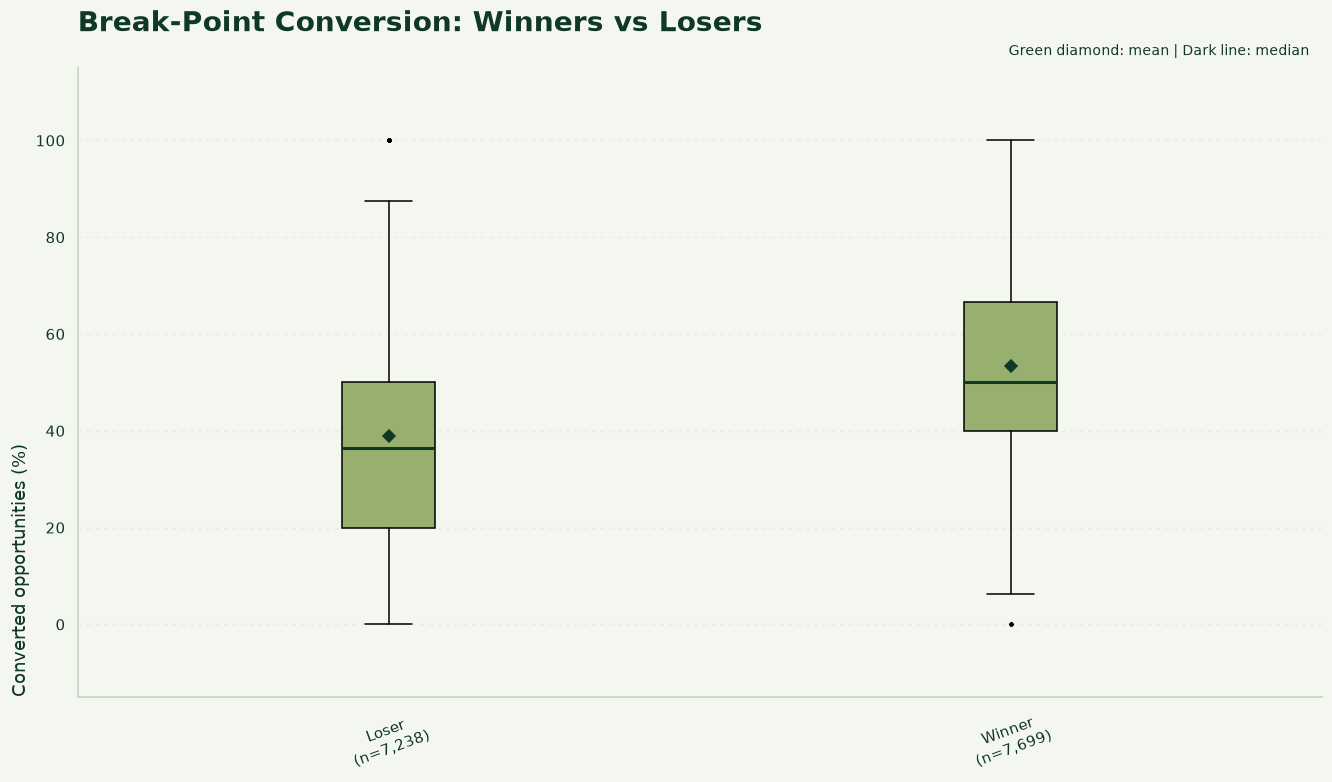

In [44]:
q20_CREAM = '#F4F6F0'
q20_WHITE = '#FFFFFF'
q20_LIME = '#C4D600'
q20_OLIVE = '#5A7263'
q20_GREEN = '#0F3826'
q20_RED = '#C86D51'
q20_GRAY = '#98B06F'
q20_INK = '#0F3826'
q20_fig, q20_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q20_fig.set_facecolor(q20_CREAM)
q20_ax.set_facecolor(q20_WHITE)
q20_groups = list(q20_r.index)
q20_values = [q20_box.loc[q20_box.group.eq(q20_g), 'value'].dropna() for q20_g in q20_groups]
q20_bp = q20_ax.boxplot(q20_values, tick_labels=[f'{q20_g}\n(n={len(q20_v):,})' for q20_g, q20_v in zip(q20_groups, q20_values)], patch_artist=True, showmeans=True, meanprops={'marker': 'D', 'markerfacecolor': q20_GREEN, 'markeredgecolor': q20_GREEN}, medianprops={'color': q20_INK, 'linewidth': 2}, flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.25})
for q20_patch in q20_bp['boxes']:
    q20_patch.set_facecolor(q20_GRAY)
q20_ax.tick_params(axis='x', labelrotation=20)
q20_ax.margins(y=0.15)
q20_ax.text(0.99, 1.015, 'Green diamond: mean | Dark line: median', transform=q20_ax.transAxes, ha='right', va='bottom', fontsize=9, color=q20_INK)
q20_ax.set_title('Break-Point Conversion: Winners vs Losers', loc='left', fontsize=18, fontweight='bold', color=q20_INK, pad=24)
q20_ax.set_ylabel('Converted opportunities (%)', fontsize=12, color=q20_INK,loc= 'bottom')
q20_ax.spines[['top', 'right']].set_visible(False)
q20_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q20_ax.tick_params(colors=q20_INK, labelsize=10)
q20_ax.set_axisbelow(True)
q20_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q20_fig.set_facecolor(q20_CREAM)
q20_ax.set_facecolor(q20_WHITE)
q20_ax.patch.set_alpha(0)
sns.despine(ax=q20_ax, top=True, right=True)
q20_ax.tick_params(length=0, pad=8)
q20_fig.savefig(FIG/'q20.svg',bbox_inches='tight',facecolor=q20_CREAM)
q20_fig.savefig(FIG / 'q20.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q20_fig)

**پاسخ محاسبه‌شده: {'Loser': 38.946899035284034, 'Winner': 53.44638509325515}**

میانگین تبدیل فرصت بریک برای برندگان ۵۳٫۴۵٪ و برای بازندگان ۳۸٫۹۵٪ است. اختلاف حدود ۱۴٫۵۰ واحد درصد است که نشان می‌دهد برندگان در استفاده از فرصت‌های ایجادشده عملکرد مؤثرتری دارند. این شاخص می‌تواند برای ارزیابی تصمیم‌گیری در امتیازهای حساس و عملکرد ذهنی بازیکن مفید باشد.
این مقایسه فقط افرادی را شامل می‌شود که حداقل یک فرصت بریک دارند. نداشتن فرصت با استفاده‌نکردن از فرصت متفاوت است. درصد در فرصت‌های کم ناپایدار است؛ مربی باید تعداد فرصت‌ها و کیفیت حریف را نیز در تفسیر دخالت دهد. 

## 21
##  فاصله از مسابقه قبلی چه ارتباطی با نرخ برد دارد؟

## How is observed recovery time associated with match-win rate?

In [45]:
q21_rest = long.sort_values(['player_id', 'date', 'match_id']).copy()
q21_rest['gap_days'] = q21_rest.groupby('player_id').date.diff().dt.total_seconds() / 86400
q21_rest['rest_group'] = pd.cut(q21_rest.gap_days, bins=[0, 1.5, 3.5, 7.5, np.inf], labels=['Up to 1.5 days', '1.5–3.5 days', '3.5–7.5 days', 'Over 7.5 days'])
q21_summary = q21_rest.groupby('rest_group', observed=True).won.agg(['mean', 'count'])
q21_r = q21_summary['mean'] * 100
q21_answer = q21_r.to_dict()
ipy_display(q21_summary)
q21_summary.to_csv(OUT / 'rest_context.csv', encoding='utf-8-sig')
save_result(21, q21_r)

,mean,count
rest_group,,
Up to 1.5 days,0.487481,6031
1.5–3.5 days,0.499052,2637
3.5–7.5 days,0.531638,3224
Over 7.5 days,0.518667,3241


,mean
rest_group,
Up to 1.5 days,48.748135
1.5–3.5 days,49.905195
3.5–7.5 days,53.163772
Over 7.5 days,51.866708


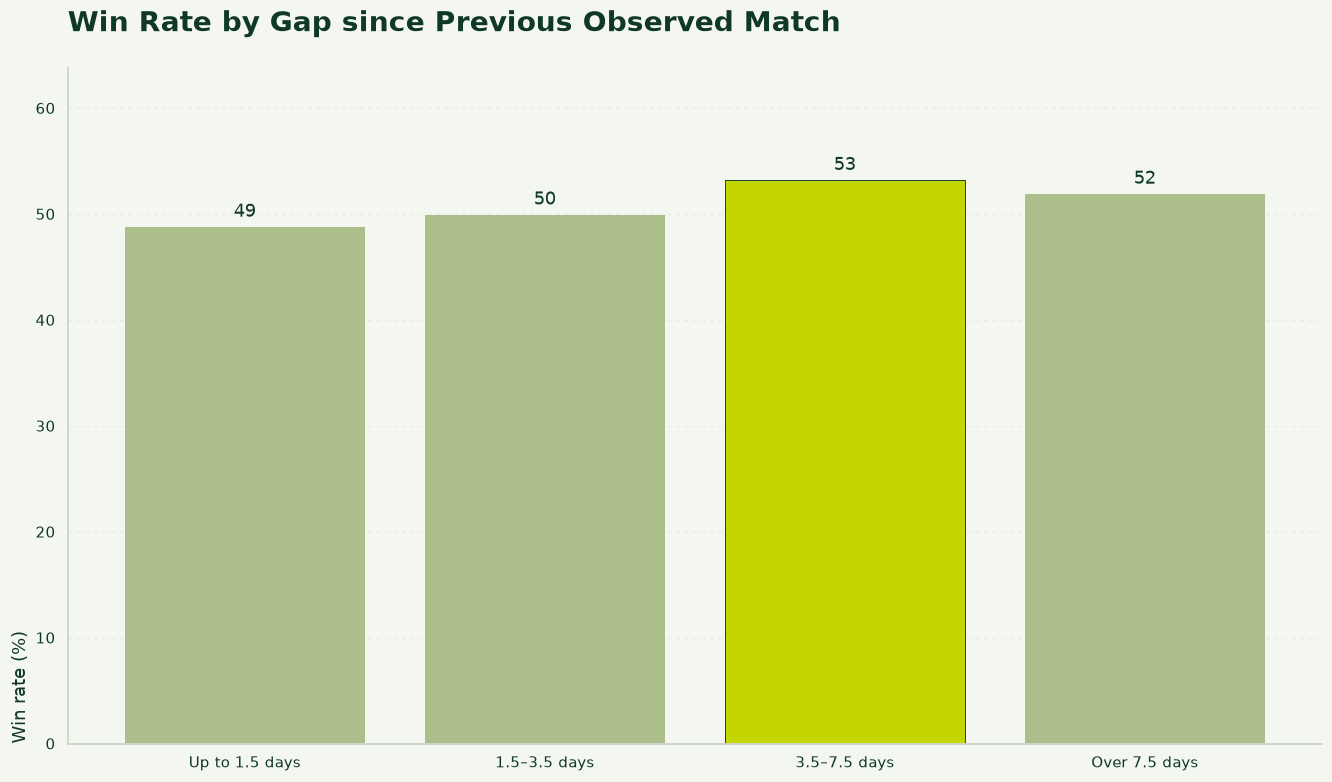

In [46]:
q21_CREAM = '#F4F6F0'
q21_WHITE = '#FFFFFF'
q21_LIME = '#C4D600'
q21_OLIVE = '#5A7263'
q21_GREEN = '#0F3826'
q21_RED = '#C86D51'
q21_GRAY = '#98B06F'
q21_INK = '#0F3826'
q21_fig, q21_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q21_fig.set_facecolor(q21_CREAM)
q21_ax.set_facecolor(q21_WHITE)
q21_shown = q21_r
q21_ax.bar(q21_shown.index.astype(str), q21_shown.values, color=[q21_GREEN if q21_v == q21_shown.max() else q21_GRAY for q21_v in q21_shown])
q21_ax.bar_label(q21_ax.containers[0], fmt='%.0f', padding=4, color=q21_INK)
q21_ax.margins(y=0.2)
for q21_bar in q21_ax.containers[0]:
    q21_bar.set_edgecolor('none')
    q21_bar.set_alpha(0.78)
q21_peak = max((q21_bar.get_width() if 21 in [3,6,9] else q21_bar.get_height()) for q21_bar in q21_ax.containers[0])
for q21_bar in q21_ax.containers[0]:
    if abs((q21_bar.get_width() if 21 in [3,6,9] else q21_bar.get_height()) - q21_peak) < 1e-9:
        q21_bar.set_facecolor(q21_LIME)
        q21_bar.set_edgecolor(q21_GREEN)
        q21_bar.set_linewidth(0.6)
        q21_bar.set_alpha(1)
q21_ax.set_title('Win Rate by Gap since Previous Observed Match', loc='left', fontsize=18, fontweight='bold', color=q21_INK, pad=24)
q21_ax.set_ylabel('Win rate (%)', fontsize=12, color=q21_INK,loc= 'bottom')
q21_ax.spines[['top', 'right']].set_visible(False)
q21_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q21_ax.tick_params(colors=q21_INK, labelsize=10)
q21_ax.set_axisbelow(True)
q21_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q21_fig.set_facecolor(q21_CREAM)
q21_ax.set_facecolor(q21_WHITE)
q21_ax.patch.set_alpha(0)
sns.despine(ax=q21_ax, top=True, right=True)
q21_ax.tick_params(length=0, pad=8)
q21_fig.savefig(FIG/'q21.svg',bbox_inches='tight',facecolor=q21_CREAM)
q21_fig.savefig(FIG / 'q21.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q21_fig)



بیشترین نرخ برد مربوط به بازیکنانی است که بین ۳٫۵ تا ۷٫۵ روز از مسابقهٔ قبلی فاصله داشته‌اند؛ نرخ برد این گروه حدود ۵۳٫۱۶٪ است. نرخ برد گروه‌های دیگر پایین‌تر یا نزدیک به آن است. این نتیجه می‌تواند نشان دهد استراحت متوسط با آمادگی بهتر همراه است، اما رابطهٔ مشاهده‌شده علت و معلولی نیست و عواملی مانند سطح حریف، مرحلهٔ تورنمنت و تعداد مسابقات نیز اثر دارند.

## 22
## زمان مسابقه در مراحل مختلف تورنمنت چه تفاوتی دارد؟

## How does match duration vary between tournament stages?

In [47]:
q22_box = matches.loc[matches.duration_complete, ['round_name', 'duration_hours']].rename(columns={'round_name': 'group', 'duration_hours': 'value'}).dropna()
q22_box['group'] = q22_box['group'].replace({'Quarterfinals': 'Quarterfinal', 'Semifinals': 'Semifinal', 'Finals': 'Final'})
q22_counts = q22_box.group.value_counts()
q22_box = q22_box.loc[q22_box.group.isin(q22_counts[q22_counts >= 20].index)]
q22_r = q22_box.groupby('group').value.agg(['mean', 'median', 'count']).sort_values('median')
q22_answer = q22_r['mean'].to_dict()
q22_order = ['Qualification round 1', 'Qualification round 2', 'Round of 128', 'Round of 64', 'Round of 32', 'Round of 16', 'Quarterfinal', 'Semifinal', 'Final']
q22_r = q22_r.reindex([q22_g for q22_g in q22_order if q22_g in q22_r.index])
save_result(22, q22_r)

,mean,median,count
group,,,
Qualification round 1,1.834273,1.560833,599
Qualification round 2,2.121253,1.907500,47
Round of 128,2.354408,1.713333,121
Round of 64,1.914149,1.624167,170
Round of 32,2.011818,1.675556,2669
Round of 16,1.948844,1.704444,1723
Quarterfinal,2.066706,1.762222,937
Semifinal,2.010581,1.766667,468
Final,1.793447,1.708472,220


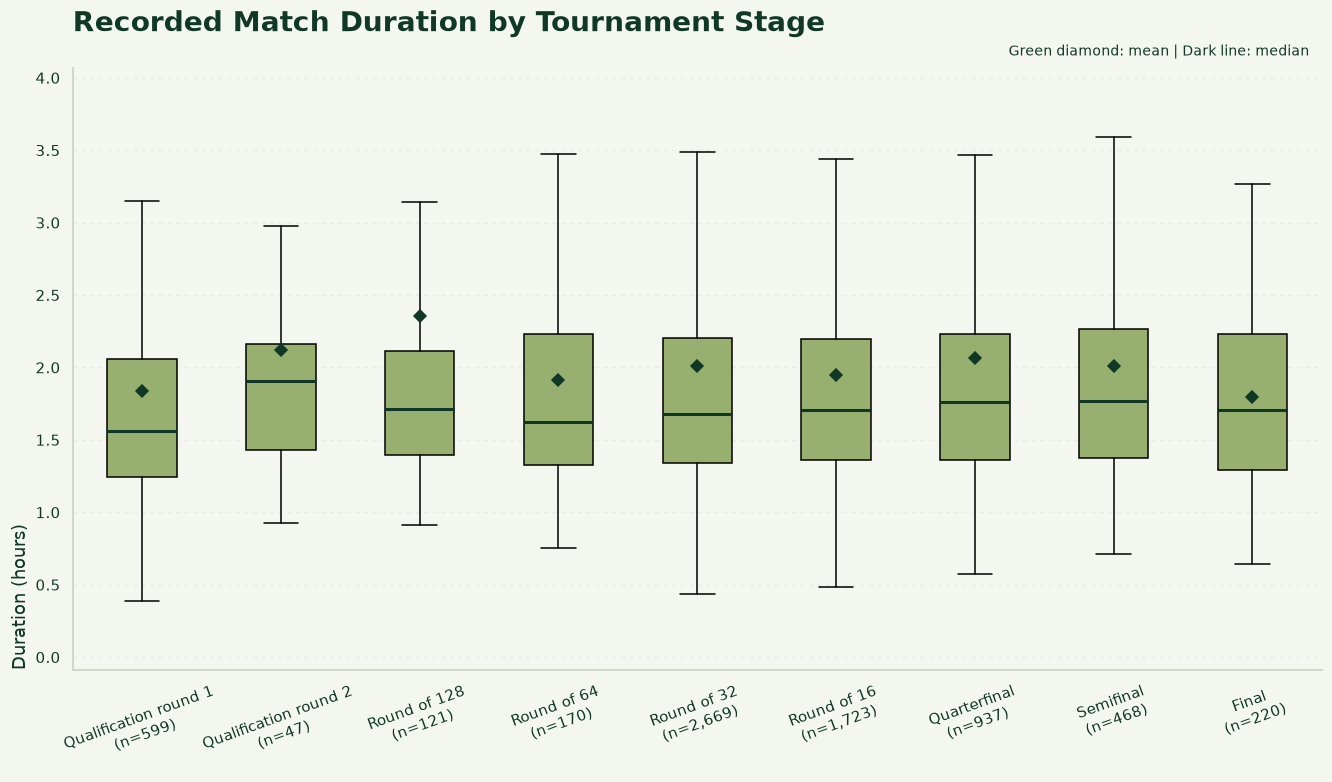

In [48]:
q22_CREAM = '#F4F6F0'
q22_WHITE = '#FFFFFF'
q22_LIME = '#C4D600'
q22_OLIVE = '#5A7263'
q22_GREEN = '#0F3826'
q22_RED = '#C86D51'
q22_GRAY = '#98B06F'
q22_INK = '#0F3826'
q22_fig, q22_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q22_fig.set_facecolor(q22_CREAM)
q22_ax.set_facecolor(q22_WHITE)
q22_groups = list(q22_r.index)
q22_values = [q22_box.loc[q22_box.group.eq(q22_g), 'value'].dropna() for q22_g in q22_groups]
q22_bp = q22_ax.boxplot(q22_values, tick_labels=[f'{q22_g}\n(n={len(q22_v):,})' for q22_g, q22_v in zip(q22_groups, q22_values)], patch_artist=True, showmeans=True, showfliers=False, meanprops={'marker': 'D', 'markerfacecolor': q22_GREEN, 'markeredgecolor': q22_GREEN}, medianprops={'color': q22_INK, 'linewidth': 2}, flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.25})
for q22_patch in q22_bp['boxes']:
    q22_patch.set_facecolor(q22_GRAY)
q22_ax.tick_params(axis='x', labelrotation=20)
q22_ax.margins(y=0.15)
q22_ax.text(0.99, 1.015, 'Green diamond: mean | Dark line: median', transform=q22_ax.transAxes, ha='right', va='bottom', fontsize=9, color=q22_INK)
q22_ax.set_title('Recorded Match Duration by Tournament Stage', loc='left', fontsize=18, fontweight='bold', color=q22_INK, pad=24)
q22_ax.set_ylabel('Duration (hours)', fontsize=12, color=q22_INK,loc= 'bottom')
q22_ax.spines[['top', 'right']].set_visible(False)
q22_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q22_ax.tick_params(colors=q22_INK, labelsize=10)
q22_ax.set_axisbelow(True)
q22_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q22_fig.set_facecolor(q22_CREAM)
q22_ax.set_facecolor(q22_WHITE)
q22_ax.patch.set_alpha(0)
sns.despine(ax=q22_ax, top=True, right=True)
q22_ax.tick_params(length=0, pad=8)
q22_fig.savefig(FIG/'q22.svg',bbox_inches='tight',facecolor=q22_CREAM)
q22_fig.savefig(FIG / 'q22.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q22_fig)

بیشترین میانگین مدت مسابقه در مرحلهٔ Round of 128 با حدود ۲٫۳۵ ساعت ثبت شده است. میانگین مدت در فینال حدود ۱٫۷۹ ساعت است. این اختلاف ممکن است به تفاوت سطح رقبا، تعداد بازی‌ها، حجم نمونه و ویژگی مسابقات مقدماتی مربوط باشد؛ بنابراین نمی‌توان نتیجه گرفت که مراحل ابتدایی همیشه طولانی‌تر از فینال هستند.

## 23
## آیا بازیکنان با رتبه نزدیک‌تر بیشتر به ست تعیین‌کننده می‌رسند؟

## Do similarly ranked opponents reach a deciding set more often?

In [49]:
q23_rankgap = (matches.h_current_rank - matches.a_current_rank).abs()
q23_valid = matches.h_current_rank.gt(0) & matches.a_current_rank.gt(0)
q23_maxsets = numeric(matches.default_period_count)
q23_valid &= q23_maxsets.isin([3, 5]) & matches.sets_recorded.gt(0)
q23_competitive = pd.DataFrame({'gap': q23_rankgap[q23_valid], 'deciding': matches.sets_recorded[q23_valid].eq(q23_maxsets[q23_valid])})
q23_competitive['band'] = pd.cut(q23_competitive.gap, [-1, 10, 50, 100, 250, np.inf], labels=['0–10', '11–50', '51–100', '101–250', '251+'])
q23_summary = q23_competitive.groupby('band', observed=True).deciding.agg(['mean', 'count'])
q23_r = q23_summary['mean'] * 100
q23_answer = q23_r.to_dict()
ipy_display(q23_summary)
q23_summary.to_csv(OUT / 'ranking_gap_context.csv', encoding='utf-8-sig')
save_result(23, q23_r)

,mean,count
band,,
0–10,0.364764,403
11–50,0.338802,1402
51–100,0.357492,1228
101–250,0.320621,2255
251+,0.286607,3360


,mean
band,
0–10,36.476427
11–50,33.880171
51–100,35.749186
101–250,32.062084
251+,28.660714


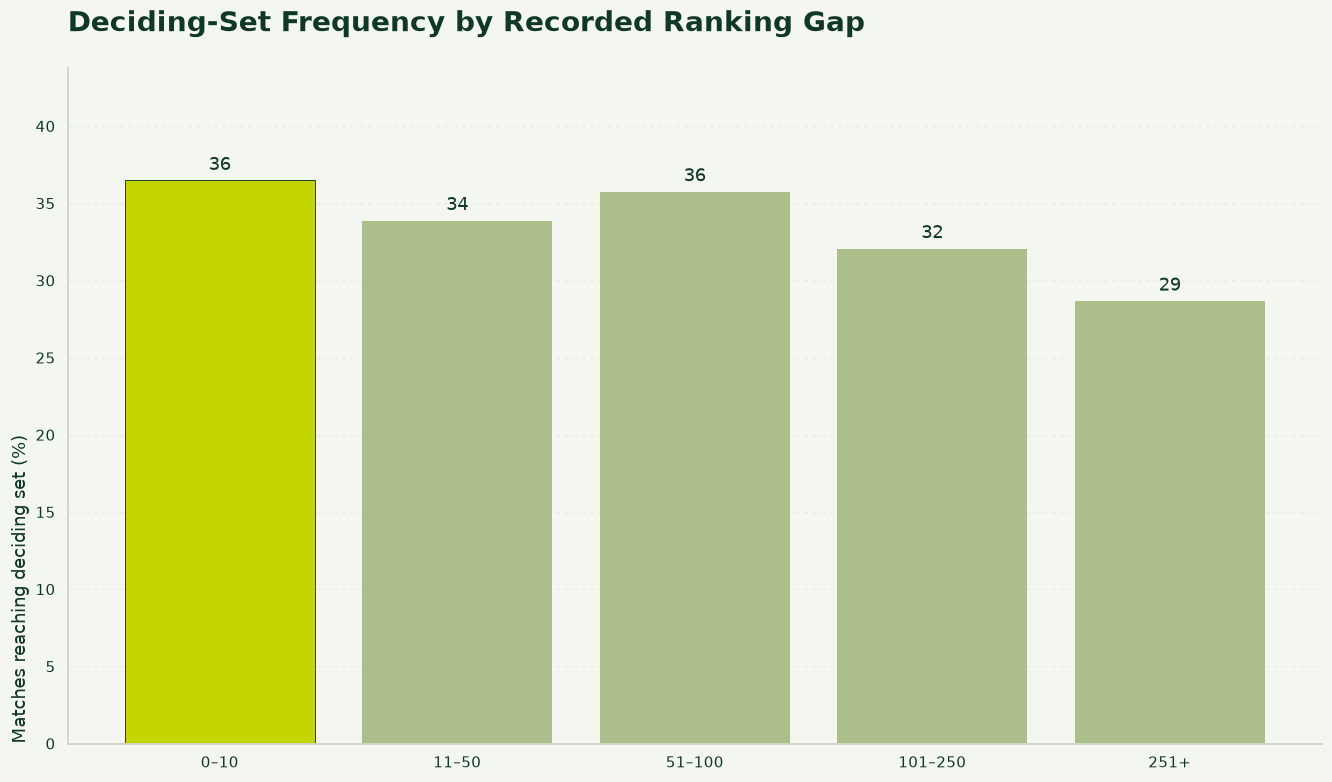

In [50]:
q23_CREAM = '#F4F6F0'
q23_WHITE = '#FFFFFF'
q23_LIME = '#C4D600'
q23_OLIVE = '#5A7263'
q23_GREEN = '#0F3826'
q23_RED = '#C86D51'
q23_GRAY = '#98B06F'
q23_INK = '#0F3826'
q23_fig, q23_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q23_fig.set_facecolor(q23_CREAM)
q23_ax.set_facecolor(q23_WHITE)
q23_shown = q23_r
q23_ax.bar(q23_shown.index.astype(str), q23_shown.values, color=[q23_GREEN if q23_v == q23_shown.max() else q23_GRAY for q23_v in q23_shown])
q23_ax.bar_label(q23_ax.containers[0], fmt='%.0f', padding=4, color=q23_INK)
q23_ax.margins(y=0.2)
for q23_bar in q23_ax.containers[0]:
    q23_bar.set_edgecolor('none')
    q23_bar.set_alpha(0.78)
q23_peak = max((q23_bar.get_width() if 23 in [3,6,9] else q23_bar.get_height()) for q23_bar in q23_ax.containers[0])
for q23_bar in q23_ax.containers[0]:
    if abs((q23_bar.get_width() if 23 in [3,6,9] else q23_bar.get_height()) - q23_peak) < 1e-9:
        q23_bar.set_facecolor(q23_LIME)
        q23_bar.set_edgecolor(q23_GREEN)
        q23_bar.set_linewidth(0.6)
        q23_bar.set_alpha(1)
q23_ax.set_title('Deciding-Set Frequency by Recorded Ranking Gap', loc='left', fontsize=18, fontweight='bold', color=q23_INK, pad=24)
q23_ax.set_ylabel('Matches reaching deciding set (%)', fontsize=12, color=q23_INK,loc= 'bottom')
q23_ax.spines[['top', 'right']].set_visible(False)
q23_ax.spines[['left', 'bottom']].set_color('#D0D7CA')
q23_ax.tick_params(colors=q23_INK, labelsize=10)
q23_ax.set_axisbelow(True)
q23_ax.grid(axis='y', linestyle=(0,(3,4)), color='#E6EAE2', alpha=0.9, linewidth=0.8)
q23_fig.set_facecolor(q23_CREAM)
q23_ax.set_facecolor(q23_WHITE)
q23_ax.patch.set_alpha(0)
sns.despine(ax=q23_ax, top=True, right=True)
q23_ax.tick_params(length=0, pad=8)
q23_fig.savefig(FIG/'q23.svg',bbox_inches='tight',facecolor=q23_CREAM)
q23_fig.savefig(FIG / 'q23.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(q23_fig)

مسابقات میان بازیکنان دارای رتبهٔ بسیار نزدیک، یعنی اختلاف رتبهٔ صفر تا ۱۰، حدود ۳۶٫۴۸٪ احتمال رسیدن به ست تعیین‌کننده داشته‌اند. این مقدار برای اختلاف رتبهٔ بالاتر از ۲۵۱ به حدود ۲۸٫۶۶٪ کاهش می‌یابد. بنابراین به‌طور کلی، رقابت میان بازیکنان هم‌سطح‌تر احتمال مسابقهٔ نزدیک و رسیدن به ست تعیین‌کننده را افزایش می‌دهد؛ هرچند روند کاملاً یکنواخت نیست و عوامل دیگری مانند سطح تورنمنت و فرم بازیکنان نیز مؤثرند.


## 24

##  نوع زمین مسابقه  چه تاثیر بر مدت زمان مسابقه دارد

## How does the type of race surface affect the duration of the race?

In [51]:

q24_pbp = pd.read_parquet(PACKAGE / 'silver' / 'clean_point_by_point.parquet')
q24_surface = matches[['match_id', 'tour_ground_type', 'duration_hours']].copy()
q24_surface['surface'] = q24_surface['tour_ground_type'].fillna('Unknown')
q24_score_cols = [f'hs_period_{i}' for i in range(1, 6)] + [f'as_period_{i}' for i in range(1, 6)]
q24_scores = matches[q24_score_cols].apply(pd.to_numeric, errors='coerce')
q24_surface['games_total'] = q24_scores.sum(axis=1, min_count=2).to_numpy()
q24_points = q24_pbp.groupby('match_id').size().rename('points_recorded')
q24_games = q24_pbp.groupby('match_id').game_id.nunique().rename('games_with_points')
q24_surface = q24_surface.set_index('match_id').join([q24_points, q24_games])
q24_surface['points_per_game_proxy'] = q24_surface['points_recorded'] / q24_surface['games_with_points'].replace(0, np.nan)
q24_r = (q24_surface.reset_index()
         .groupby('surface')
         .agg(matches=('match_id', 'size'),
              mean_duration_hours=('duration_hours', 'mean'),
              mean_games=('games_total', 'mean'),
              mean_points_per_game=('points_per_game_proxy', 'mean'))
         .sort_values('mean_duration_hours', ascending=False))
q24_r.to_csv(OUT / 'q24_surface_duration.csv', encoding='utf-8-sig')
plt.show(); plt.close(q24_fig)
display(q24_r.round(2))

NameError: name 'q24_fig' is not defined

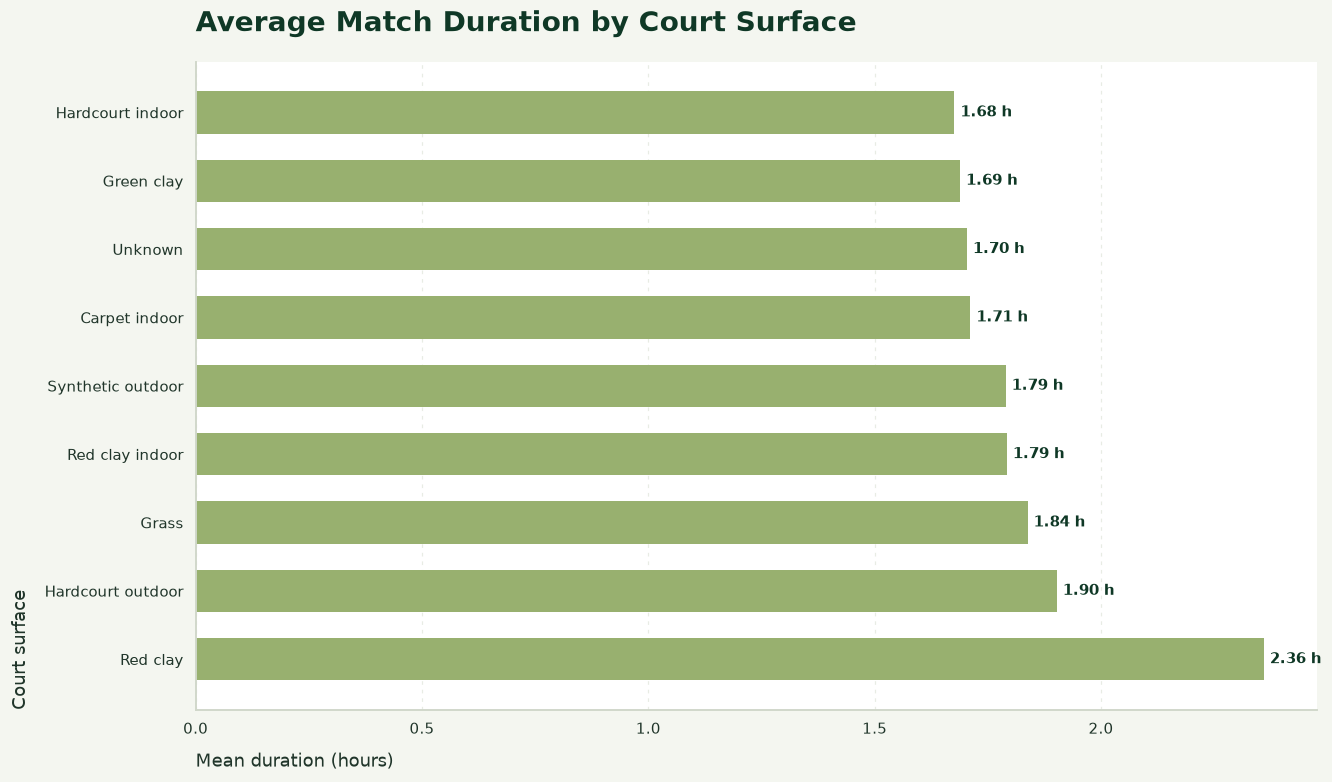

In [ ]:
CREAM = '#F4F6F0'
WHITE = '#FFFFFF'
LIME = '#C4D600'
OLIVE = '#5A7263'
GREEN = '#0F3826'
RED = '#C86D51'
GRAY = '#98B06F'
INK = '#0F3826'
GRID = '#E6EAE2'
BORDER = '#D0D7CA'
TEXT = '#20352A'

q24_fig, q24_ax = plt.subplots(figsize=(12, 7), layout='constrained')
q24_fig.set_facecolor(CREAM)
q24_ax.set_facecolor(WHITE)
q24_bars = q24_ax.barh(q24_r.index.astype(str), q24_r['mean_duration_hours'], color=GRAY, edgecolor='none', height=.62)
q24_ax.bar_label(q24_bars, labels=[f'{v:.2f} h' for v in q24_r['mean_duration_hours']], padding=4, color=GREEN, fontsize=10, fontweight='bold')
q24_ax.set_title('Average Match Duration by Court Surface', loc='left', fontsize=18, fontweight='bold', color=GREEN, pad=20)
q24_ax.set_xlabel('Mean duration (hours)', fontsize=12, color=TEXT, labelpad=10, loc='left')
q24_ax.set_ylabel('Court surface', fontsize=12, color=TEXT, labelpad=10, loc='bottom')
q24_ax.spines[['top', 'right']].set_visible(False)
q24_ax.spines[['left', 'bottom']].set_color(BORDER)
q24_ax.tick_params(colors=TEXT, labelsize=10, length=0, pad=8)
q24_ax.grid(axis='x', linestyle=(0, (3, 4)), color=GRID, alpha=.9, linewidth=.8)
q24_ax.grid(axis='y', visible=False)
q24_fig.savefig(FIG / 'q24_surface_duration.svg', bbox_inches='tight', facecolor=CREAM)
q24_fig.savefig(FIG / 'q24_surface_duration.png', dpi=220, bbox_inches='tight', facecolor=CREAM)


نتایج نشان می‌دهد مسابقات روی Red clay با میانگین حدود ۲٫۳۶ ساعت طولانی‌ترین زمان را دارند. پس از آن، Hardcourt outdoor با ۱٫۹۰ ساعت و Grass با ۱٫۸۴ ساعت قرار می‌گیرند. تعداد گیم‌ها بین سطوح تفاوت زیادی ندارد؛ بنابراین افزایش زمان در زمین خاکی احتمالاً به طولانی‌تر شدن رالی‌ها و کندتر بودن جریان بازی مربوط است. البته شاخص نقاط به‌ازای هر گیم، جایگزین تقریبی طول رالی است و طول واقعی رالی را مستقیماً اندازه‌گیری نمی‌کند

## 25


## آیا نظر سنجی ها و پیش بینی های تماشاگران قبل از مسابقه یک تخمین گربی طرف و دقیق از نتیجه بازی است یا دچار تعصبات شناختی مثل طرفداری از بازیکنان مشهور یا ستاره ها فارغ از آمادگی فعلی و نوع زمین میشود؟

## Are fan votes and pre-match predictions an unbiased and accurate estimator of match outcomes, or do they suffer from cognitive biases such as favoring popular or star players regardless of surface suitability and ?current form


In [ ]:
q27_votes = pd.read_parquet(PACKAGE / 'silver' / 'clean_votes.parquet')
q27_r = (matches[['match_id', 'winner_code', 'tour_ground_type']]
         .merge(q27_votes[['match_id', 'home_vote', 'away_vote']], on='match_id', how='inner')
         .dropna(subset=['winner_code', 'home_vote', 'away_vote']).copy())
q27_r[['home_vote', 'away_vote']] = q27_r[['home_vote', 'away_vote']].apply(pd.to_numeric, errors='coerce')
q27_r = q27_r[(q27_r['home_vote'] + q27_r['away_vote']) > 0].copy()
q27_r['predicted_code'] = np.where(q27_r['home_vote'] >= q27_r['away_vote'], 1, 2)
q27_r['correct'] = q27_r['predicted_code'].eq(q27_r['winner_code'])
q27_total_votes = q27_r['home_vote'] + q27_r['away_vote']
q27_r['winner_vote_share'] = np.where(q27_r['winner_code'].eq(1), q27_r['home_vote'] / q27_total_votes, q27_r['away_vote'] / q27_total_votes)
q27_overall = pd.DataFrame({
    'matches_with_votes': [len(q27_r)],
    'vote_accuracy_pct': [q27_r['correct'].mean() * 100],
    'winner_vote_share_pct': [q27_r['winner_vote_share'].mean() * 100],
    'disagreements': [(~q27_r['correct']).sum()]})

plt.show(); plt.close(q27_fig)
display(q27_overall.round(2)); display(q27_surface.round(2))

,matches_with_votes,vote_accuracy_pct,winner_vote_share_pct,disagreements
0,8744,66.03,59.53,2970


,matches,accuracy_pct,winner_vote_share_pct
tour_ground_type,,,
Carpet indoor,81,61.73,57.35
Synthetic outdoor,83,63.86,58.58
Hardcourt indoor,1509,64.55,59.10
Red clay,2713,66.16,59.21
Hardcourt outdoor,4059,66.17,59.65
Grass,82,69.51,62.20
Unknown,91,70.33,63.61
Red clay indoor,108,75.00,64.54
Green clay,18,77.78,68.46


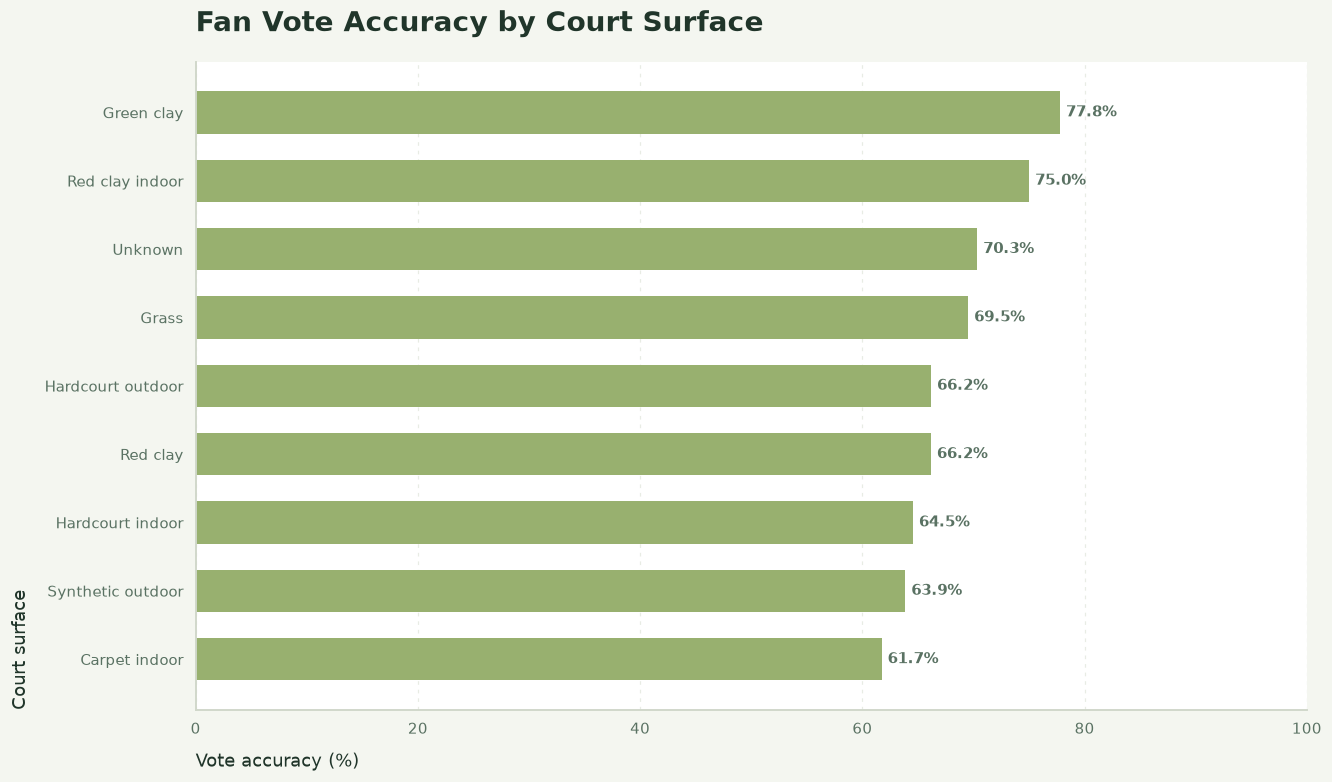

In [ ]:
CREAM = '#F4F6F0'
WHITE = '#FFFFFF'
LIME = '#C4D600'
OLIVE = '#5A7263'
GREEN = '#0F3826'
RED = '#C86D51'
GRAY = '#98B06F'
INK = '#0F3826'
GRID = '#E6EAE2'
BORDER = '#D0D7CA'
TEXT = '#20352A'

q27_surface = (q27_r.groupby(q27_r['tour_ground_type'].fillna('Unknown')).agg(
        matches=('match_id', 'size'),
        accuracy_pct=('correct', lambda x: x.mean() * 100),
        winner_vote_share_pct=('winner_vote_share', lambda x: x.mean() * 100))
    .sort_values('accuracy_pct', ascending=True))
q27_surface.to_csv(OUT / 'q27_fan_vote_by_surface.csv',encoding='utf-8-sig')
q27_fig, q27_ax = plt.subplots(figsize=(12, 7),layout='constrained')
q27_fig.set_facecolor(CREAM)
q27_ax.set_facecolor(WHITE)
q27_bars = q27_ax.barh(q27_surface.index.astype(str), q27_surface['accuracy_pct'],color=GRAY,height=0.62,edgecolor='none')
q27_ax.bar_label(q27_bars, labels=[f'{value:.1f}%' for value in q27_surface['accuracy_pct']],padding=4,color=OLIVE,fontsize=10,fontweight='bold')
q27_ax.set_title('Fan Vote Accuracy by Court Surface',loc='left',fontsize=18,fontweight='bold',color=TEXT,pad=20)
q27_ax.set_xlabel('Vote accuracy (%)',fontsize=12,color=TEXT,labelpad=10, loc='left')
q27_ax.set_ylabel('Court surface',fontsize=12,color=TEXT,labelpad=10, loc='bottom')
q27_ax.set_xlim(0, 100)
q27_ax.set_xticks(np.arange(0, 101, 20))
q27_ax.spines[['top', 'right']].set_visible(False)
q27_ax.spines[['left', 'bottom']].set_color(BORDER)
q27_ax.tick_params(axis='both', colors=OLIVE,labelsize=10,length=0,pad=8)
q27_ax.grid( axis='x', linestyle=(0, (3, 4)), color=GRID, alpha=0.9, linewidth=0.8)
q27_ax.grid(axis='y', visible=False)
q27_fig.savefig( FIG / 'q27_fan_vote_accuracy.svg', bbox_inches='tight', facecolor=CREAM)
q27_fig.savefig( FIG / 'q27_fan_vote_accuracy.png',dpi=220, bbox_inches='tight', facecolor=CREAM)
plt.show()
plt.close(q27_fig)

رأی هواداران در 66.0% از مسابقات دارای رأی با نتیجهٔ واقعی هماهنگ بوده است. اختلاف رأی و نتیجه نشان می‌دهد محبوبیت می‌تواند با توان واقعی بازیکن متفاوت باشد؛ بنابراین رأی هواداران سیگنال پیش‌بینی است، نه معیار قطعی و بی‌طرف.

In [ ]:
assert players.player_id.is_unique
assert matches.match_id.is_unique
assert len(long) == 2 * len(matches)
assert long.won.sum() == len(matches)
assert q06_country.Wins.sum() == len(matches)
assert q06_country.Appearances.sum() == 2 * len(matches)
assert q16_top_table['sum'].le(q16_top_table['count']).all()
assert q16_top_table.rate.between(0, 100).all()
assert players.height_cm.dropna().between(100, 250).all()
assert complete.shape == (len(matches), 5)
assert matches.duration_hours.dropna().gt(0).all()
assert not q09_finals.duplicated(['tour_tournament_id', 'season_season_id', 'gender', 'month']).any()
assert all(((OUT / f'q{i:02d}.csv').exists() for i in range(1, 24)))
assert all(((FIG / f'q{i:02d}.png').exists() for i in range(1, 24)))
print('Structural checks passed. All 23 result tables and figures exist.')
assert len(gold_check)==len(m)
assert q19_box.value.between(0,100).all()
assert q20_box.value.between(0,100).all()
assert q06_country.Wins.sum()==len(matches)
print('New-package and percentage-range checks passed.')

Structural checks passed. All 23 result tables and figures exist.
New-package and percentage-range checks passed.
